# Comparación de modelos — IC por bootstrap

Notebook **reutilizable** para comparar modelos por sus métricas de validación
con intervalos de confianza (bootstrap *cluster* a nivel línea).

1. **Errorbar**: punto ± IC95% por métrica — la vista *fiel* al IC del bootstrap.
2. **Boxplot** con bigotes en los percentiles 2.5/97.5 (= el IC95%) + cuartiles.

In [2]:
import os
import sys
import pathlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Detectar la raíz del repo (donde vive src/) y pararse ahí: así los paths
# relativos de los configs (data/..., configs/...) resuelven como en train.py.
ROOT = pathlib.Path.cwd()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.training.save_model import (
    load_cached_results,
    results_cache_key,
    save_cached_results,
)
from src.training.run import run_evaluation
from src.utils.config import load_config
from src.utils.seed import set_seed
from src.training.sweep import best_config_from_sweep, best_run_from_sweep
from src.training.select import config_with_nested_dim

print("repo root:", ROOT)

repo root: c:\Users\MODDE\Desktop\Udesa\ML\PF\maze-genomic-pred


In [4]:
# === Modelos a comparar =====================================================
# Baseline GBLUP sin PCA, y DOS formas de elegir la dim de PCA (para ver cómo el
# método de selección cambia la conclusión):
#   (A) del SWEEP de wandb -> dim que maximiza Pearson en val 2019 (el MISMO set
#       donde después comparás): es lo estándar, pero el número del ganador queda
#       OPTIMISTA (winner's curse).
#   (B) ANIDADA -> dim elegida en un inner-val ANTERIOR (2018, train 2017) sin
#       tocar 2019: comparación honesta. Solo dims < ~900 (techo de rango p≫n).
from src.training.sweep import best_config_from_sweep, best_run_from_sweep
from src.training.select import config_with_nested_dim

SWEEP_PATH  = "oromagnoli-/maze-genomic-pred/ziu59tim"   # sweep de dim de PCA (split fijo)
PCA_BASE    = "configs/exp_pca_gblup_2017_2018_to_2019.yaml"
DIM_KEY     = "preprocess.pca.n_components"
NESTED_DIMS = [16, 32, 64, 128, 256, 512]                # elegibles en inner-2018 (n=901)

CONFIGS = {"GBLUP sin PCA (REML)": "configs/exp_gblup_2017_2018_to_2019.yaml"}

# (A) mejor del sweep — selección sobre val 2019 (OPTIMISTA)
try:
    ov, best_val, rid = best_run_from_sweep(SWEEP_PATH)
    a_dim = ov.get(DIM_KEY, "?")
    print(f"(A) sweep   -> dim={a_dim}  pearson_r_mean(val 2019)={best_val:.4f}  (run {rid})  [OPTIMISTA]")
    CONFIGS[f"PCA-{a_dim} (elegida en 2019)"] = best_config_from_sweep(SWEEP_PATH, PCA_BASE)
except Exception as e:
    print(f"[warn] no pude leer el sweep ({e}); salteo la opción (A)")

# (B) selección anidada — inner-val 2018, no toca 2019 (HONESTA)
cfg_nested, sel = config_with_nested_dim(PCA_BASE, DIM_KEY, NESTED_DIMS, inner_val_year=2018)
scores_2018 = {k: round(v, 3) for k, v in sel["scores"].items()}
print(f"(B) anidada -> dim={sel['best']}  (mejor en inner-2018; scores={scores_2018})  [HONESTA]")
CONFIGS[f"PCA-{sel['best']} (elegida en 2018)"] = cfg_nested

# Portada primero (pearson_r). matching20 = coincidence index del top-20% (utilidad
# para SELECCIONAR líneas; ver la sección de matching20 al final). Al estar en METRICS
# aparece en todos los df/plots; su IC sale del mismo bootstrap cluster por línea.
METRICS = ("pearson_r", "rmse", "r2", "matching20")
N_BOOT = 2000      # réplicas de bootstrap (más = IC más estable)
ALPHA = 0.05       # IC del (1-alpha); 0.05 -> IC 95% (percentiles 2.5 / 97.5)

# Evita reentrenar modelos si ya hay resultados cacheados. OJO: se bumpeó la versión
# de métricas (matching20), así que la primera corrida tras el cambio recomputa todo
# (cache miss por key nueva) — los modelos torch (AE/MLP) necesitan su entorno.
USE_CACHE = True

FIG_DIR = ROOT / "experiments" / "figs"   
FIG_DIR.mkdir(parents=True, exist_ok=True)

wandb: [wandb.Api()] Loaded credentials for https://api.wandb.ai from C:\Users\MODDE\.netrc.


(A) sweep   -> dim=1000  pearson_r_mean(val 2019)=0.3402  (run x00g6302)  [OPTIMISTA]
(B) anidada -> dim=128  (mejor en inner-2018; scores={16: 0.331, 32: 0.22, 64: 0.327, 128: 0.378, 256: 0.342, 512: 0.234})  [HONESTA]


In [5]:
import copy

# Curvas de entrenamiento por modelo (history_ del MLP: train_loss y, si hubo
# inner-val, val_*). Lo llena evaluate_model como efecto lateral; lo usa la sección
# de learning curves del MLP más abajo. {nombre: [{"fold", "history": [...]}]}.
CURVES_BY_MODEL = {}

def evaluate_model(name, config, *, n_boot=N_BOOT, alpha=ALPHA, use_cache=USE_CACHE):
    '''Corre run_evaluation (sin wandb) con bootstrap forzado y devuelve:
       - filas tidy [{model, metric, point, lo, hi, n}]
       - dict {metric: samples} con la distribución bootstrap por métrica.
    `config` puede ser una RUTA a un YAML o un dict de config ya armado (p.ej. el
    que devuelve best_config_from_sweep). Asume split fijo (un único fold de val).

    Con use_cache=True NO reentrena si ya hay resultados cacheados para esta
    (config, seed, n_boot, alpha): los levanta de disco. En miss evalúa y guarda.'''
    cfg = load_config(config) if isinstance(config, str) else copy.deepcopy(config)
    set_seed(int(cfg.get("seed", 575)))
    cfg.setdefault("bootstrap", {})
    cfg["bootstrap"].update(enabled=True, n_boot=n_boot, alpha=alpha)  # IC siempre on

    key = results_cache_key(cfg, n_boot=n_boot, alpha=alpha)
    res = load_cached_results(key) if use_cache else None
    if res is None:
        res = run_evaluation(cfg)              # sin log_fn => no toca wandb
        save_cached_results(key, res)          # cachea para las próximas corridas
    else:
        print(f"  [cache hit] {name} ({key})")

    fold = res["per_fold"][-1]                 # split fijo: el (único) fold de val
    boot = res["bootstrap"][-1] if res["bootstrap"] else {}
    CURVES_BY_MODEL[name] = res.get("histories", [])   # learning curves (si el modelo las expone)

    rows, samples = [], {}
    for m in METRICS:
        rows.append({
            "model": name, "metric": m,
            "point": float(fold.get(m, np.nan)),
            "lo": float(fold.get(f"{m}_lo", np.nan)),
            "hi": float(fold.get(f"{m}_hi", np.nan)),
            "n": int(fold.get("n", 0)),        # n de val (para el k=top-20% del matching)
        })
        samples[m] = np.asarray(boot.get(m, []), dtype=float)
    return rows, samples

In [16]:
rows, samples_by_model = [], {}
for name, path in CONFIGS.items():
    r, s = evaluate_model(name, path)
    rows.extend(r)
    samples_by_model[name] = s
    print(f"[ok] {name}")

df = pd.DataFrame(rows)
df

  [cache hit] GBLUP sin PCA (REML) (5690a3fc84e2f561)
[ok] GBLUP sin PCA (REML)
  [cache hit] PCA-1000 (elegida en 2019) (6c0327c0a61150b5)
[ok] PCA-1000 (elegida en 2019)
  [cache hit] PCA-128 (elegida en 2018) (2fc385ed4f01c1dc)
[ok] PCA-128 (elegida en 2018)


,model,metric,point,lo,hi,n
0,GBLUP sin PCA (REML),pearson_r,0.314528,0.246174,0.377771,722
1,GBLUP sin PCA (REML),rmse,1.301634,1.239727,1.363143,722
2,GBLUP sin PCA (REML),r2,-0.664404,-0.873739,-0.490156,722
3,GBLUP sin PCA (REML),matching20,0.395833,0.333333,0.465278,722
4,PCA-1000 (elegida en 2019),pearson_r,0.340193,0.274056,0.403527,722
5,PCA-1000 (elegida en 2019),rmse,1.301215,1.236220,1.364775,722
6,PCA-1000 (elegida en 2019),r2,-0.663332,-0.878916,-0.485362,722
7,PCA-1000 (elegida en 2019),matching20,0.416667,0.340278,0.472222,722
8,PCA-128 (elegida en 2018),pearson_r,0.245375,0.180659,0.306936,722
9,PCA-128 (elegida en 2018),rmse,1.311948,1.250326,1.369933,722


In [17]:
# === Test PAREADO de la diferencia vs la REFERENCIA (modelo[0] = baseline) =====
# Comparar dos boxplots marginales NO dice si A le gana a B: se solapan por el
# ruido COMPARTIDO de qué líneas caen en val (afecta a los dos igual). Lo correcto
# es la diferencia sobre el MISMO resample: run_evaluation corre el bootstrap de
# cada modelo con la misma seed y el mismo grupo de líneas, así
# samples_X[b] - samples_ref[b] es un bootstrap PAREADO válido (ese ruido se
# cancela). Referencia = 1er modelo (baseline); comparamos cada otro contra él.
ref = list(samples_by_model)[0]
qlo, qhi = 100 * ALPHA / 2, 100 * (1 - ALPHA / 2)
for name in list(samples_by_model)[1:]:
    print(f"\n{name}  -  {ref}:")
    for m in METRICS:
        sx, sr = samples_by_model[name][m], samples_by_model[ref][m]
        n = min(len(sx), len(sr))
        d = (sx[:n] - sr[:n]); d = d[np.isfinite(d)]
        if d.size == 0:                      # p.ej. matching20 all-nan / sin muestras
            print(f"  {m:>9}: (sin muestras finitas; reinicia el kernel y recompute)")
            continue
        lo, hi = np.nanpercentile(d, [qlo, qhi])
        sig = "SIGNIFICATIVA" if (lo > 0 or hi < 0) else "no significativa (IC incluye 0)"
        print(f"  {m:>9}: delta = {np.mean(d):+.4f}  IC95% [{lo:+.4f}, {hi:+.4f}]  -> {sig}")
print("\nOJO: la dim 'elegida en 2019' se seleccionó sobre ESTE mismo val 2019 -> su "
      "delta es un techo OPTIMISTA (post-selección). La 'elegida en 2018' es la "
      "comparación honesta. La adjudicación final es 2020, sellado.")


PCA-1000 (elegida en 2019)  -  GBLUP sin PCA (REML):
  pearson_r: delta = +0.0255  IC95% [+0.0025, +0.0489]  -> SIGNIFICATIVA
       rmse: delta = -0.0002  IC95% [-0.0230, +0.0216]  -> no significativa (IC incluye 0)
         r2: delta = +0.0004  IC95% [-0.0560, +0.0589]  -> no significativa (IC incluye 0)
  matching20: delta = +0.0109  IC95% [-0.0417, +0.0625]  -> no significativa (IC incluye 0)

PCA-128 (elegida en 2018)  -  GBLUP sin PCA (REML):
  pearson_r: delta = -0.0689  IC95% [-0.1022, -0.0369]  -> SIGNIFICATIVA
       rmse: delta = +0.0102  IC95% [-0.0175, +0.0372]  -> no significativa (IC incluye 0)
         r2: delta = -0.0259  IC95% [-0.0941, +0.0451]  -> no significativa (IC incluye 0)
  matching20: delta = -0.0776  IC95% [-0.1389, -0.0139]  -> SIGNIFICATIVA

OJO: la dim 'elegida en 2019' se seleccionó sobre ESTE mismo val 2019 -> su delta es un techo OPTIMISTA (post-selección). La 'elegida en 2018' es la comparación honesta. La adjudicación final es 2020, sellado.


## 1) Errorbar — punto ± IC95%

La forma más fiel de mostrar el IC: el punto es la estimación sobre validación y
los bigotes son los percentiles 2.5 / 97.5 del bootstrap. Ideal para comparar
varios modelos de un vistazo.

In [ ]:
# plot_ci centralizado en src/eval/report_plots.py (convención del proyecto: los notebooks
# solo importan y llaman funciones de src/; así cada sección puede levantarlo y correr sola).
# Un subplot por métrica: punto (estimación sobre val) ± bigotes en los percentiles 2.5/97.5
# (= IC95% del bootstrap). Ideal para comparar varios modelos de un vistazo.
from src.eval.report_plots import plot_ci

fig = plot_ci(df)
fig.savefig(FIG_DIR / "ci_errorbars.png", dpi=150, bbox_inches="tight")
plt.show()


## 2) Boxplot de la distribución bootstrap

Un boxplot por default pone los bigotes en 1.5·IQR, que **no** es tu IC. El truco:
`whis=(2.5, 97.5)` deja los bigotes exactamente en el **IC95%**. La caja sigue
mostrando los cuartiles (Q1 / mediana / Q3), así ves forma + IC juntos.
(Pearson del dummy es `nan` → se saltea solo.)

In [ ]:
# plot_box centralizado en src/eval/report_plots.py. whis=(2.5, 97.5) deja los bigotes
# exactamente en el IC95%; la caja muestra los cuartiles (Q1/mediana/Q3), así ves forma + IC
# juntos. (Pearson del dummy = nan -> se saltea solo.)
from src.eval.report_plots import plot_box

for m in METRICS:
    fig = plot_box(samples_by_model, m)
    if fig is not None:
        fig.savefig(FIG_DIR / f"box_{m}.png", dpi=150, bbox_inches="tight")
        plt.show()


In [ ]:
# Diferencia PAREADA vs la referencia (1er modelo): ESTO sí mide significancia. Dos boxplots
# marginales NO alcanzan (se solapan por el ruido compartido de qué líneas caen en val); la
# resta sobre el MISMO resample lo cancela. Caja/bigotes (IC95%) que NO cruzan 0 (rojo) =>
# diferencia significativa. plot_paired_diff vive en src/eval/report_plots.py.
from src.eval.report_plots import plot_paired_diff

fig = plot_paired_diff(samples_by_model, metrics=METRICS)
fig.savefig(FIG_DIR / "box_paired_diff.png", dpi=150, bbox_inches="tight")
plt.show()


## Notas

- **Un solo fold**: con el split fijo (train 2017-18 / val 2019) hay un único fold
  de validación; el notebook toma ese. El test 2020 queda intocable.
- **Reproducible**: el bootstrap usa la seed del config; misma config → mismo IC.
- **Caché**: con `USE_CACHE = True` cada modelo se evalúa una sola vez por
  (config, seed, `N_BOOT`, `ALPHA`); las corridas siguientes levantan el resultado
  de `outputs/eval_cache` sin reentrenar. Cambiar un hiperparámetro del config
  invalida su entrada sola; poné `USE_CACHE = False` para forzar recómputo.
- **Modelos entrenados**: para reusar un modelo/encoder sin reentrenar, `scripts/train.py` lo guarda como wandb
  Artifact + copia local; se carga con `load_model_artifact(...)` pasando los
  `train_years` del fold para que el chequeo anti-leakage corte cualquier fuga.
- **Figuras**: se guardan en `FIG_DIR` (`experiments/figs`, gitignored)

## Autoencoder por dimensión vs GBLUP

El AE comprime los ~4.6k SNPs binarios a un latente de dimensión fija (regla 4: salida
sigmoide + BCE). Corrimos **un sweep bayesiano por dimensión** — 32 / 64 / 128 / 256 —
minimizando la **BCE de reconstrucción en 2018**. Acá traemos el **mejor AE de cada
dimensión** (`val_bce_best` mínimo) y lo probamos como compresor aguas abajo de GBLUP,
igual que PCA: el `AutoencoderReducer` **re-ajusta el AE train-only en cada fold**
(regla 1) — con la *receta* de HP del sweep, reentrenada en 2017+2018 para reportar en
val 2019 (no se reusan los pesos del sweep, que eran de 2017). Comparamos cada `AE-d`
contra el baseline GBLUP **y** contra `PCA-d` de la **misma dimensión** (no lineal vs
lineal). El test 2020 queda sellado.

In [21]:
from src.training.ae_select import best_ae_from_sweep
from src.utils.config import set_nested

GBLUP_BASE = "configs/exp_gblup_2017_2018_to_2019.yaml"   # GBLUP sin compresor (baseline, modelo[0])

# sweep_id por dimensión latente del AE (cada uno minimiza val_bce_best = BCE recon 2018).
AE_SWEEPS = {
    32:  "oromagnoli-/maze-genomic-pred/eer2osdp",
    64:  "oromagnoli-/maze-genomic-pred/2g38s9q3",
    128: "oromagnoli-/maze-genomic-pred/8lgjyjvv",
    256: "oromagnoli-/maze-genomic-pred/qj9pqf6w",
}

ae_rows, AE_CONFIGS = [], {}
for dim, sweep in AE_SWEEPS.items():
    info = best_ae_from_sweep(sweep)                # baja meta + pesos del mejor trial del sweep
    hp   = dict(info["meta"].get("ae_params", {}))  # RECETA de HP (se re-entrena train-only; los pesos del sweep eran de 2017)
    met  = info["meta"].get("metrics", {})
    assert int(hp.get("latent_dim")) == dim, (dim, hp.get("latent_dim"))
    ae_rows.append({
        "dim": dim, "run": info["run_id"],
        "val_bce_best": round(float(info["metric_value"]), 4),
        "recon_acc":    round(float(met.get("ae_val_recon_acc_best", np.nan)), 4),
        "encoder_hidden": hp.get("encoder_hidden"), "activation": hp.get("activation"),
        "lr": round(float(hp.get("lr", np.nan)), 5),
        "dropout":     round(float(hp.get("dropout", 0.0)), 3),
        "denoising_p": round(float(hp.get("denoising_p", 0.0)), 3),
        "batchnorm": hp.get("batchnorm"), "batch_size": hp.get("batch_size"),
    })
    # GBLUP sobre el embedding del AE = base GBLUP (sin pca) + bloque autoencoder. El
    # AutoencoderReducer re-ajusta el AE train-only en cada fold (regla 1): con esta
    # receta de HP, reentrenado en 2017+2018 para reportar en val 2019.
    cfg = load_config(GBLUP_BASE)
    cfg["preprocess"] = {"autoencoder": hp}
    cfg["artifacts"]  = {"save_model": False}
    AE_CONFIGS[f"AE-{dim} + GBLUP"] = cfg

ae_df = pd.DataFrame(ae_rows).sort_values("dim").reset_index(drop=True)
print("Mejor AE por dimensión (seleccionado por BCE de reconstrucción en val 2018):")
ae_df

wandb:   2 of 2 files downloaded.  
wandb:   2 of 2 files downloaded.  
wandb:   2 of 2 files downloaded.  
wandb:   2 of 2 files downloaded.  


Mejor AE por dimensión (seleccionado por BCE de reconstrucción en val 2018):


,dim,run,val_bce_best,recon_acc,encoder_hidden,activation,lr,dropout,denoising_p,batchnorm,batch_size
0,32,f14m0ycx,0.4920,0.7687,[512],leaky_relu,0.00114,0.184,0.027,True,256
1,64,pz76geun,0.4751,0.7790,[1024],elu,0.00054,0.283,0.062,True,256
2,128,xn75e6c8,0.4599,0.7897,[1024],leaky_relu,0.00052,0.252,0.014,True,128
3,256,ylkkuejq,0.4521,0.7923,[512],elu,0.00021,0.054,0.016,True,128


In [22]:
# Para cada dim agregamos el AE (no lineal) y PCA de la MISMA dimensión (lineal),
# además del baseline GBLUP sin compresión. Todo sobre el split fijo train 2017+2018
# -> val 2019, con IC95% por bootstrap cluster a nivel línea (evaluate_model + caché).
DIM_CONFIGS = {"GBLUP sin PCA (REML)": GBLUP_BASE}
for dim in AE_SWEEPS:
    DIM_CONFIGS[f"AE-{dim} + GBLUP"] = AE_CONFIGS[f"AE-{dim} + GBLUP"]
    cfg_pca = load_config(PCA_BASE); set_nested(cfg_pca, DIM_KEY, dim)
    DIM_CONFIGS[f"PCA-{dim}"] = cfg_pca

dim_rows, dim_samples = [], {}
for name, cfg in DIM_CONFIGS.items():
    r, s = evaluate_model(name, cfg)
    dim_rows.extend(r); dim_samples[name] = s
    print(f"[ok] {name}")

dim_df = pd.DataFrame(dim_rows)
# Vista de portada: Pearson (predicho-observado) por modelo, con su IC95%.
dim_df[dim_df.metric == "pearson_r"].reset_index(drop=True)

  [cache hit] GBLUP sin PCA (REML) (5690a3fc84e2f561)
[ok] GBLUP sin PCA (REML)
  [cache hit] AE-32 + GBLUP (1f24db463526d1ef)
[ok] AE-32 + GBLUP
  [cache hit] PCA-32 (3409539dd592c1da)
[ok] PCA-32
  [cache hit] AE-64 + GBLUP (7f3d95f068f3172e)
[ok] AE-64 + GBLUP
  [cache hit] PCA-64 (f7a1d7a894ef5bcb)
[ok] PCA-64
  [cache hit] AE-128 + GBLUP (36cea6cbfc5bffce)
[ok] AE-128 + GBLUP
  [cache hit] PCA-128 (2fc385ed4f01c1dc)
[ok] PCA-128
  [cache hit] AE-256 + GBLUP (10c419f92c61456c)
[ok] AE-256 + GBLUP
  [cache hit] PCA-256 (5a62768304774a5b)
[ok] PCA-256


,model,metric,point,lo,hi,n
0,GBLUP sin PCA (REML),pearson_r,0.314528,0.246174,0.377771,722
1,AE-32 + GBLUP,pearson_r,0.147911,0.082886,0.213477,722
2,PCA-32,pearson_r,0.238452,0.168610,0.303620,722
3,AE-64 + GBLUP,pearson_r,0.246216,0.182337,0.307256,722
4,PCA-64,pearson_r,0.248804,0.182051,0.309757,722
5,AE-128 + GBLUP,pearson_r,0.227220,0.162695,0.291665,722
6,PCA-128,pearson_r,0.245375,0.180659,0.306936,722
7,AE-256 + GBLUP,pearson_r,0.223852,0.152229,0.291041,722
8,PCA-256,pearson_r,0.257733,0.192142,0.321966,722


In [23]:
# Diferencia PAREADA vs el baseline GBLUP (mismo resample del bootstrap): si el IC95%
# de (modelo - baseline) no cruza 0, la diferencia es significativa. Para pearson_r/r2
# >0 = el compresor le gana al baseline; para rmse <0 = le gana (menos error).
ref = "GBLUP sin PCA (REML)"
qlo, qhi = 100 * ALPHA / 2, 100 * (1 - ALPHA / 2)
for name in [k for k in dim_samples if k != ref]:
    print(f"\n{name}  -  {ref}:")
    for m in METRICS:
        sx, sr = dim_samples[name][m], dim_samples[ref][m]
        n = min(len(sx), len(sr)); d = (sx[:n] - sr[:n]); d = d[np.isfinite(d)]
        if d.size == 0:                      # p.ej. matching20 all-nan / sin muestras
            print(f"  {m:>9}: (sin muestras finitas; reinicia el kernel y recompute)")
            continue
        lo, hi = np.nanpercentile(d, [qlo, qhi])
        sig = "SIGNIFICATIVA" if (lo > 0 or hi < 0) else "no significativa (IC incluye 0)"
        print(f"  {m:>9}: delta = {np.mean(d):+.4f}  IC95% [{lo:+.4f}, {hi:+.4f}]  -> {sig}")
print("\nOJO: la dim se evalúa acá DIRECTO sobre val 2019; elegir la mejor dim sobre "
      "este mismo set sería optimista. La selección honesta de dim va en inner-2018 "
      "(como en la sección de PCA de arriba). 2020 sellado.")


AE-32 + GBLUP  -  GBLUP sin PCA (REML):
  pearson_r: delta = -0.1661  IC95% [-0.2204, -0.1096]  -> SIGNIFICATIVA
       rmse: delta = -0.1112  IC95% [-0.1577, -0.0678]  -> SIGNIFICATIVA
         r2: delta = +0.2746  IC95% [+0.1578, +0.4060]  -> SIGNIFICATIVA
  matching20: delta = -0.1649  IC95% [-0.2431, -0.0833]  -> SIGNIFICATIVA

PCA-32  -  GBLUP sin PCA (REML):
  pearson_r: delta = -0.0759  IC95% [-0.1289, -0.0192]  -> SIGNIFICATIVA
       rmse: delta = -0.0578  IC95% [-0.1003, -0.0175]  -> SIGNIFICATIVA
         r2: delta = +0.1459  IC95% [+0.0428, +0.2648]  -> SIGNIFICATIVA
  matching20: delta = -0.1324  IC95% [-0.2153, -0.0486]  -> SIGNIFICATIVA

AE-64 + GBLUP  -  GBLUP sin PCA (REML):
  pearson_r: delta = -0.0676  IC95% [-0.1126, -0.0202]  -> SIGNIFICATIVA
       rmse: delta = -0.0451  IC95% [-0.0833, -0.0087]  -> SIGNIFICATIVA
         r2: delta = +0.1146  IC95% [+0.0211, +0.2192]  -> SIGNIFICATIVA
  matching20: delta = -0.0873  IC95% [-0.1667, -0.0069]  -> SIGNIFICATIVA

PCA-

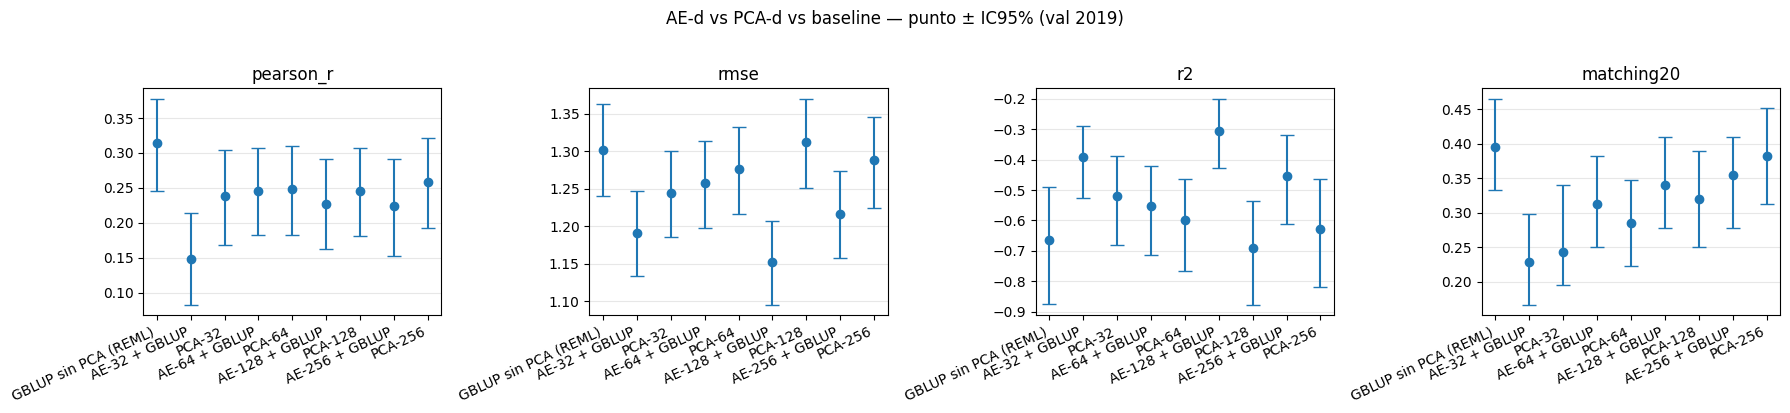

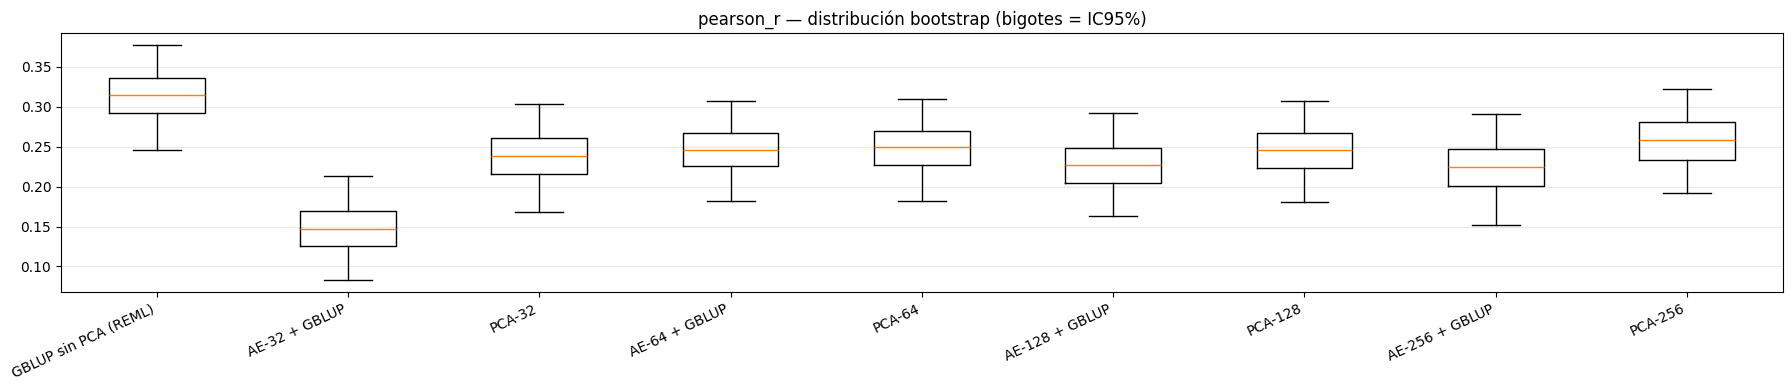

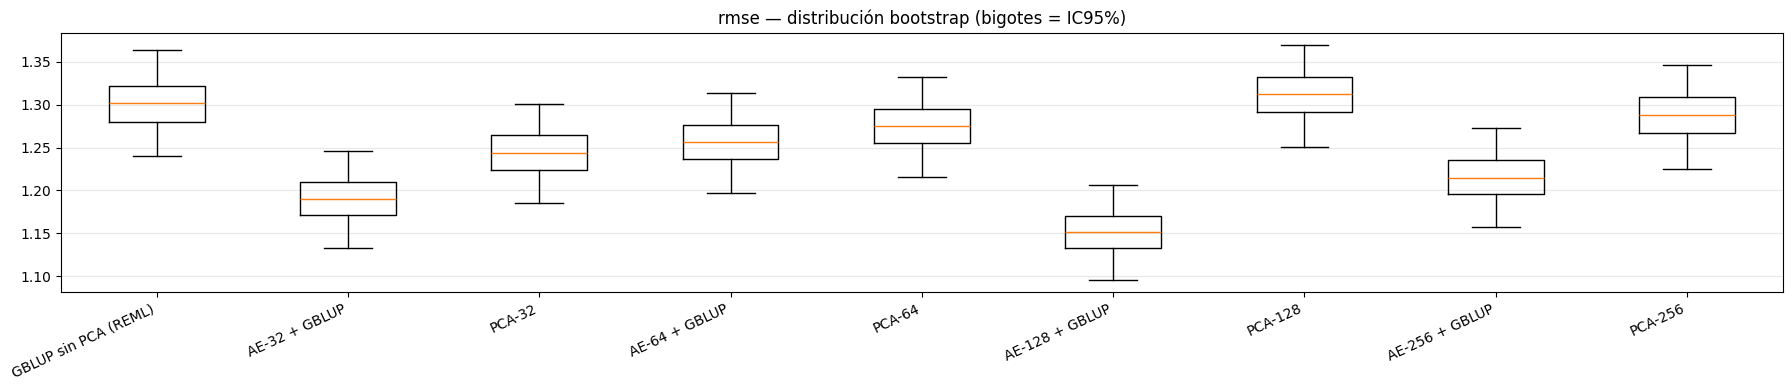

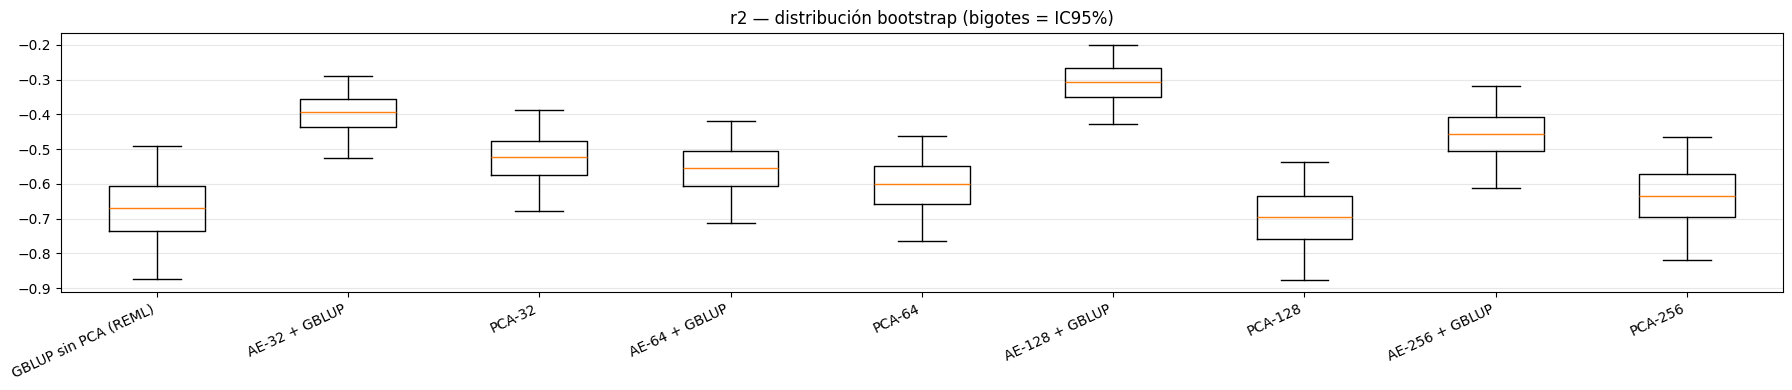

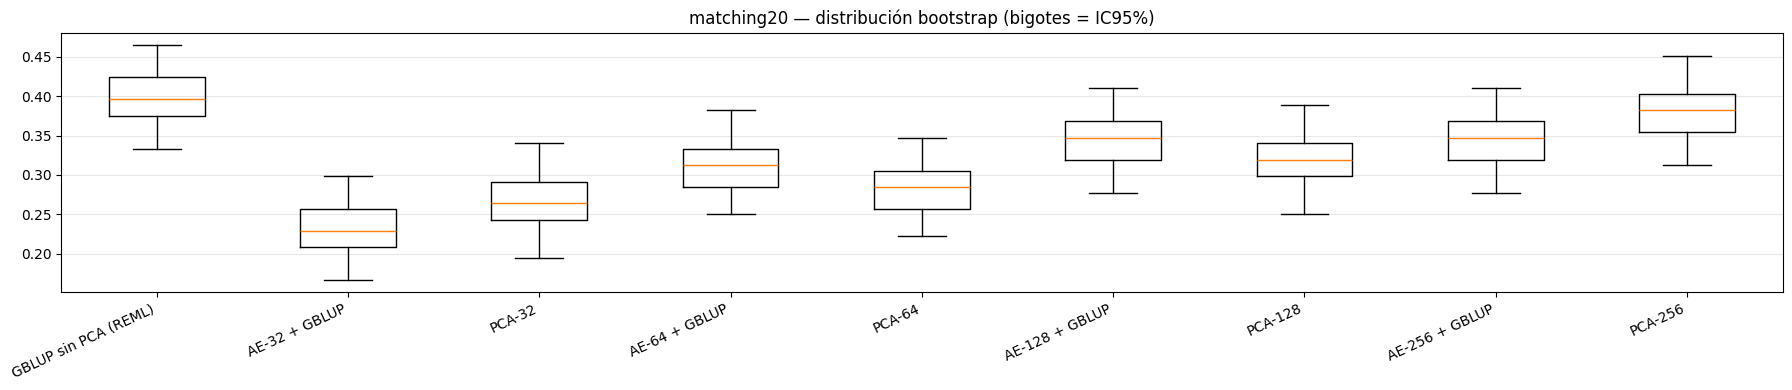

In [24]:
# Reusa los mismos gráficos de arriba sobre el set de modelos por dimensión.
fig = plot_ci(dim_df, title="AE-d vs PCA-d vs baseline — punto ± IC95% (val 2019)")
fig.savefig(FIG_DIR / "ci_errorbars_ae.png", dpi=150, bbox_inches="tight")
plt.show()

for m in METRICS:
    fig = plot_box(dim_samples, m)
    if fig is not None:
        fig.savefig(FIG_DIR / f"box_ae_{m}.png", dpi=150, bbox_inches="tight")
        plt.show()

### Lectura

**Reconstrucción (sweep).** La BCE de validación baja monótona con la dimensión
(0.492 → 0.475 → 0.460 → 0.452 para 32/64/128/256; accuracy de bits 0.77 → 0.79):
más latente reconstruye mejor, como era de esperar. Todos los ganadores usan
batchnorm, encoder de una sola capa (512/1024) y denoising/dropout suaves.

**Downstream — Pearson (métrica de portada, val 2019).** Ningún compresor le gana al
**baseline GBLUP sin comprimir** (r = 0.314): comprimir *pierde* señal de correlación.
- `AE-d` vs `PCA-d` de igual dim: **empatan en d=64** (AE 0.246 vs PCA 0.249) y **PCA
  queda por encima** en 32/128/256. El AE no lineal **no le gana a PCA** en
  correlación a ninguna dimensión.
- `AE-32` es el peor (0.148): a dimensión muy baja el cuello no lineal descarta señal
  predictiva aunque reconstruya bien.

**Downstream — RMSE / R².** Acá el AE **sí** mejora fuerte y significativo vs el
baseline: `AE-128` baja el RMSE a 1.15 (R² −0.30) contra 1.30 del baseline (R² −0.66),
ΔR² = +0.36 con IC que no cruza 0; `AE-256` y `AE-32` también mejoran RMSE/R² de forma
significativa. PCA **no** lo logra (su RMSE queda ~ baseline). El embedding del AE
**re-escala** las predicciones y reduce el error cuadrático, pero a costa del ranking
(Pearson).

**Conclusión.** La mejor reconstrucción (d=256) **no** es la que mejor predice — confirma
la decisión de tunear el AE por reconstrucción y dejar la dimensión a la selección
downstream. Con la portada en Pearson, el baseline GBLUP sigue siendo el modelo a batir
y el AE no aporta sobre PCA; el AE solo destaca en RMSE/R² (ataca la *calibración de
escala*, no el ranking). La selección honesta de dim va en inner-2018; 2020 sellado.

## XGBoost por dimensión (selección honesta 2018 → reporte 2019)

Para cada compresor corrimos un **sweep bayesiano de los HP de XGBoost** (`sweep_xgb.yaml`)
entrenando con **2017** y eligiendo por Pearson en **2018** — sin tocar 2019, así la
comparación final no sufre *winner's curse*. Acá tomamos el **mejor trial de cada
sweep**, lo **reentrenamos con 2017+2018** y lo **testeamos en 2019** con IC95% por
bootstrap, contra el baseline GBLUP. Cuatro dimensiones de AE (32/64/128/256) + un
control **PCA-128** (la mejor dim de PCA bajo selección honesta en 2018). El AE se
re-ajusta train-only por fold (regla 1). 2020 sellado.

> Nota: con un solo año de train (2017) XGBoost no puede hacer early stopping temporal,
> así que `n_estimators` fue un HP más del sweep. En el reporte se usa el valor elegido,
> reentrenando sobre 2017+2018.

In [25]:
from src.training.sweep import best_run_from_sweep

# sweep_id + config base por modelo (4 dims de AE + 1 PCA de control). El mejor trial
# de cada sweep se eligió por pearson_r_mean = Pearson en val 2018 (train 2017),
# honesto: 2019 nunca entró en la selección.
XGB_SWEEPS = {
    "XGB AE-32":   ("oromagnoli-/maze-genomic-pred/1rewf5z5", "configs/exp_xgb_ae_d32_2017_to_2018.yaml"),
    "XGB AE-64":   ("oromagnoli-/maze-genomic-pred/onke89wu", "configs/exp_xgb_ae_d64_2017_to_2018.yaml"),
    "XGB AE-128":  ("oromagnoli-/maze-genomic-pred/gz2l9qg2", "configs/exp_xgb_ae_d128_2017_to_2018.yaml"),
    "XGB AE-256":  ("oromagnoli-/maze-genomic-pred/0dbchh3l", "configs/exp_xgb_ae_d256_2017_to_2018.yaml"),
    "XGB PCA-128": ("oromagnoli-/maze-genomic-pred/dcynh8s6", "configs/exp_xgb_pca_2017_to_2018.yaml"),
}
# REPORTE honesto: HP elegidos en 2018 -> se REENTRENA con 2017+2018 y se testea en
# 2019 (val externo nunca usado para elegir). 2020 sellado.
REPORT_CV = {"scheme": "fixed_temporal", "val_year": 2019, "train_years": [2017, 2018],
             "holdout_test_year": 2020, "enforce_disjoint_lines": True}

XGB_CONFIGS = {"GBLUP sin PCA (REML)": "configs/exp_gblup_2017_2018_to_2019.yaml"}
xgb_sel = []
for name, (sweep, base) in XGB_SWEEPS.items():
    ov, p2018, rid = best_run_from_sweep(sweep)        # mejor por pearson_r_mean (val 2018)
    cfg = load_config(base)
    for k, v in ov.items():
        set_nested(cfg, k, v)                          # mejores HP de XGBoost del sweep
    cfg["cv"] = dict(REPORT_CV)                         # reentrena 2017+2018 -> testea 2019
    cfg["artifacts"] = {"save_model": False}
    XGB_CONFIGS[name] = cfg
    xgb_sel.append({
        "modelo": name, "run": rid, "pearson_val2018": round(p2018, 4),
        "n_estimators": ov.get("model.params.n_estimators"),
        "max_depth": ov.get("model.params.max_depth"),
        "lr": round(float(ov.get("model.params.learning_rate")), 4),
        "subsample": round(float(ov.get("model.params.subsample")), 3),
        "colsample": round(float(ov.get("model.params.colsample_bytree")), 3),
        "reg_lambda": round(float(ov.get("model.params.reg_lambda")), 3),
    })

xgb_sel_df = pd.DataFrame(xgb_sel)
print("Mejor trial de cada sweep (HP elegidos por Pearson en val 2018):")
xgb_sel_df

Mejor trial de cada sweep (HP elegidos por Pearson en val 2018):


,modelo,run,pearson_val2018,n_estimators,max_depth,lr,subsample,colsample,reg_lambda
0,XGB AE-32,e8zgjiq5,0.3559,1142,6,0.1253,0.644,0.836,1.145
1,XGB AE-64,oqmljr2w,0.3799,884,6,0.0190,0.551,0.946,4.370
2,XGB AE-128,iqnl4wvt,0.3934,247,6,0.0077,0.713,0.373,0.031
3,XGB AE-256,459i6sro,0.4560,499,5,0.0510,0.966,0.601,0.859
4,XGB PCA-128,8s3yclr8,0.4066,972,6,0.0061,0.850,0.627,1.267


In [26]:
# Reentrena cada mejor XGBoost con 2017+2018 y testea en 2019, con IC95% por bootstrap
# (evaluate_model + caché). Junto con el baseline GBLUP (referencia).
xgb_rows, xgb_samples = [], {}
for name, cfg in XGB_CONFIGS.items():
    r, s = evaluate_model(name, cfg)
    xgb_rows.extend(r); xgb_samples[name] = s
    print(f"[ok] {name}")

xgb_df = pd.DataFrame(xgb_rows)
# Vista de portada: Pearson por modelo en val 2019, con su IC95%.
xgb_df[xgb_df.metric == "pearson_r"].reset_index(drop=True)

  [cache hit] GBLUP sin PCA (REML) (5690a3fc84e2f561)
[ok] GBLUP sin PCA (REML)
  [cache hit] XGB AE-32 (fa8e6f8e4cd818da)
[ok] XGB AE-32
  [cache hit] XGB AE-64 (77d927b90ca28cb9)
[ok] XGB AE-64
  [cache hit] XGB AE-128 (0994f22d18a14a84)
[ok] XGB AE-128
  [cache hit] XGB AE-256 (ff396ad5bb1fbf98)
[ok] XGB AE-256
  [cache hit] XGB PCA-128 (ff1c2c6327aa5b8c)
[ok] XGB PCA-128


,model,metric,point,lo,hi,n
0,GBLUP sin PCA (REML),pearson_r,0.314528,0.246174,0.377771,722
1,XGB AE-32,pearson_r,0.245219,0.179231,0.313231,722
2,XGB AE-64,pearson_r,0.243655,0.169732,0.306431,722
3,XGB AE-128,pearson_r,0.241414,0.174128,0.303107,722
4,XGB AE-256,pearson_r,0.253264,0.183222,0.321075,722
5,XGB PCA-128,pearson_r,0.236979,0.168890,0.300639,722


In [27]:
# Diferencia PAREADA de cada XGBoost vs el baseline GBLUP (mismo resample bootstrap):
# IC95% de (modelo - baseline) que no cruza 0 => significativa. pearson_r/r2 >0 = el
# XGBoost le gana; rmse <0 = le gana (menos error).
ref = "GBLUP sin PCA (REML)"
qlo, qhi = 100 * ALPHA / 2, 100 * (1 - ALPHA / 2)
for name in [k for k in xgb_samples if k != ref]:
    print(f"\n{name}  -  {ref}:")
    for m in METRICS:
        sx, sr = xgb_samples[name][m], xgb_samples[ref][m]
        n = min(len(sx), len(sr)); d = (sx[:n] - sr[:n]); d = d[np.isfinite(d)]
        if d.size == 0:                      # p.ej. matching20 all-nan / sin muestras
            print(f"  {m:>9}: (sin muestras finitas; reinicia el kernel y recompute)")
            continue
        lo, hi = np.nanpercentile(d, [qlo, qhi])
        sig = "SIGNIFICATIVA" if (lo > 0 or hi < 0) else "no significativa (IC incluye 0)"
        print(f"  {m:>9}: delta = {np.mean(d):+.4f}  IC95% [{lo:+.4f}, {hi:+.4f}]  -> {sig}")


XGB AE-32  -  GBLUP sin PCA (REML):
  pearson_r: delta = -0.0681  IC95% [-0.1341, +0.0010]  -> no significativa (IC incluye 0)
       rmse: delta = -0.1276  IC95% [-0.1804, -0.0748]  -> SIGNIFICATIVA
         r2: delta = +0.3124  IC95% [+0.1756, +0.4551]  -> SIGNIFICATIVA
  matching20: delta = -0.1263  IC95% [-0.2083, -0.0417]  -> SIGNIFICATIVA

XGB AE-64  -  GBLUP sin PCA (REML):
  pearson_r: delta = -0.0711  IC95% [-0.1442, -0.0033]  -> SIGNIFICATIVA
       rmse: delta = -0.0659  IC95% [-0.1208, -0.0155]  -> SIGNIFICATIVA
         r2: delta = +0.1659  IC95% [+0.0376, +0.3130]  -> SIGNIFICATIVA
  matching20: delta = -0.0971  IC95% [-0.1875, -0.0069]  -> SIGNIFICATIVA

XGB AE-128  -  GBLUP sin PCA (REML):
  pearson_r: delta = -0.0726  IC95% [-0.1384, -0.0092]  -> SIGNIFICATIVA
       rmse: delta = -0.1434  IC95% [-0.1909, -0.0976]  -> SIGNIFICATIVA
         r2: delta = +0.3493  IC95% [+0.2265, +0.4825]  -> SIGNIFICATIVA
  matching20: delta = -0.1317  IC95% [-0.2083, -0.0556]  -> SIGNI

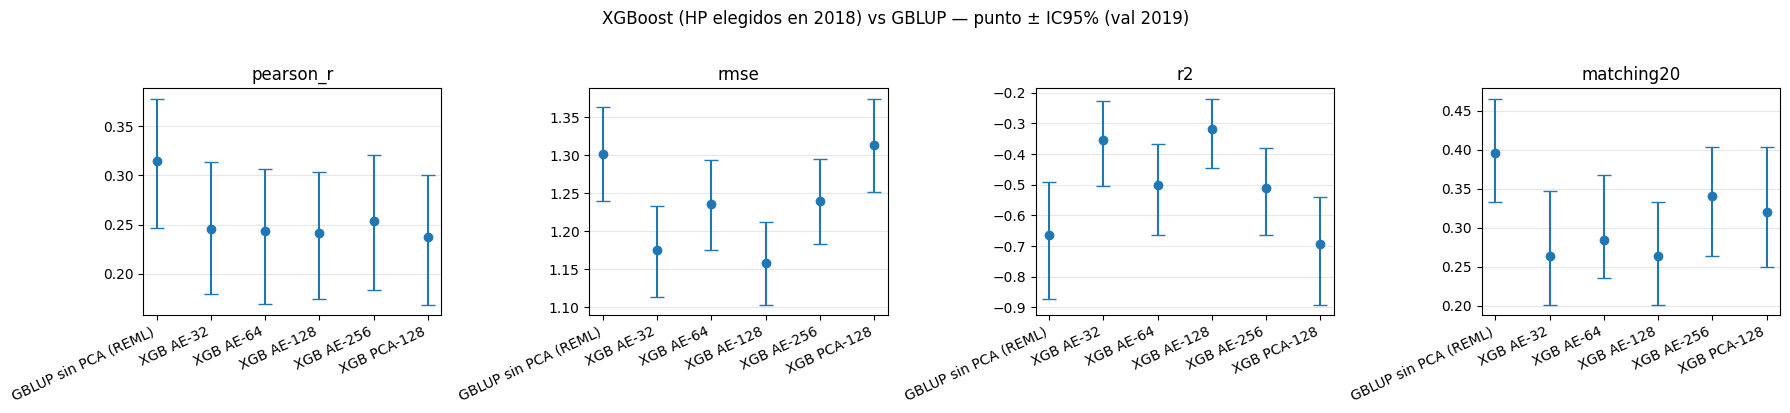

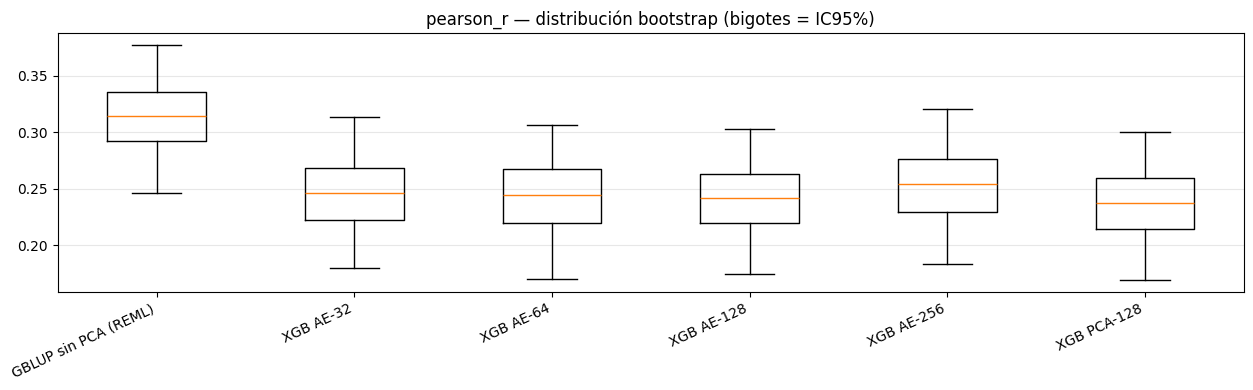

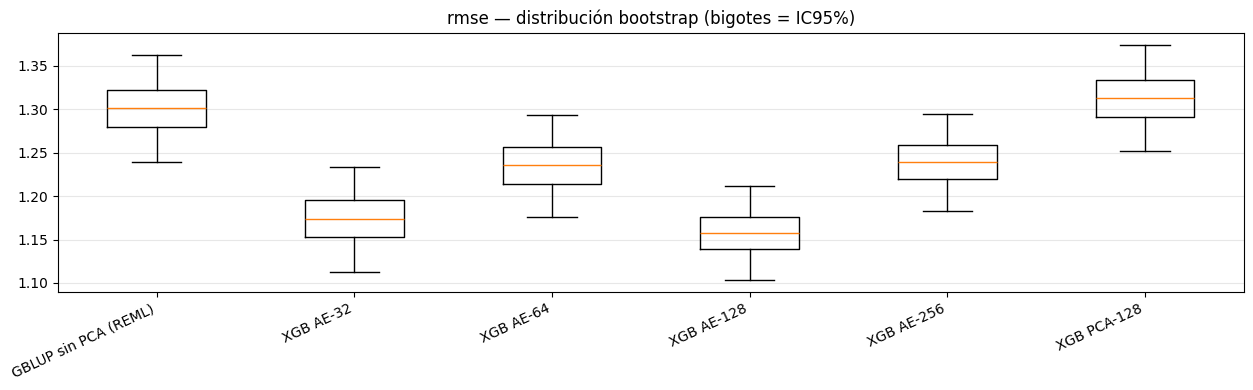

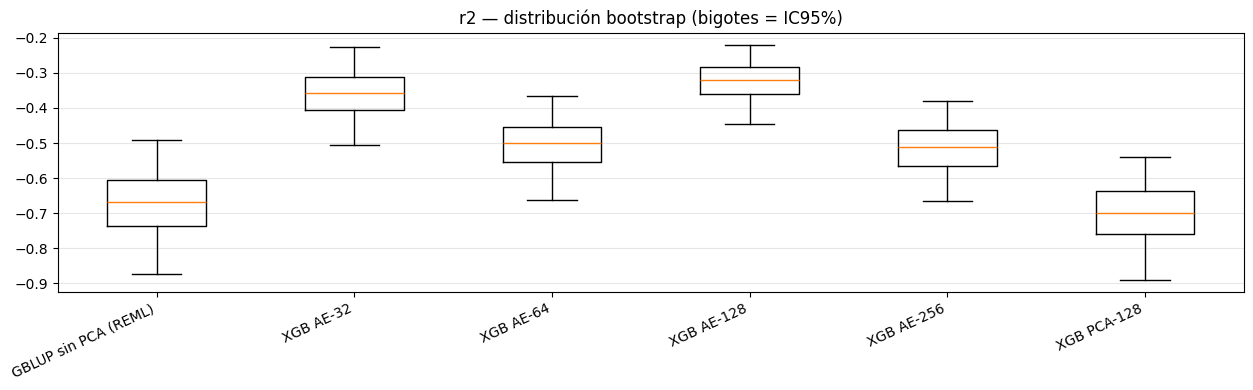

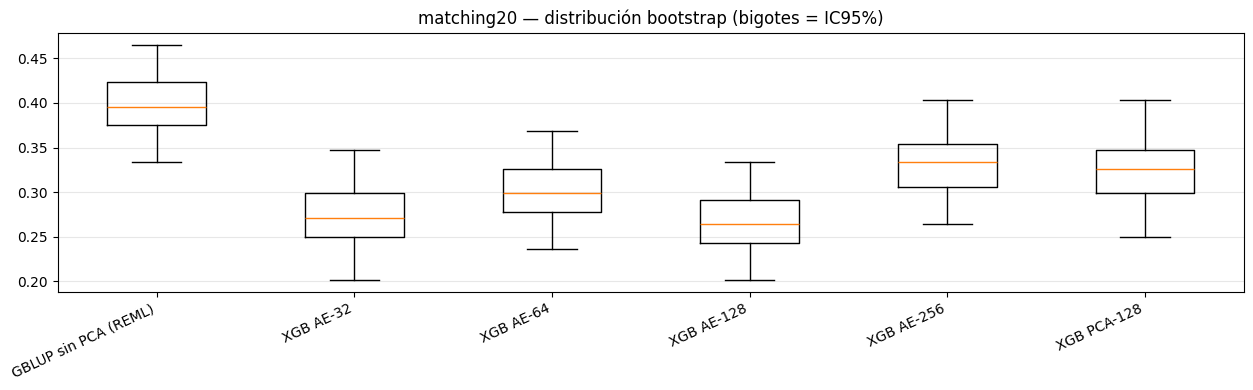

In [28]:
# Mismos gráficos sobre los XGBoost (reporte 2019) + el baseline GBLUP.
fig = plot_ci(xgb_df, title="XGBoost (HP elegidos en 2018) vs GBLUP — punto ± IC95% (val 2019)")
fig.savefig(FIG_DIR / "ci_errorbars_xgb.png", dpi=150, bbox_inches="tight")
plt.show()

for m in METRICS:
    fig = plot_box(xgb_samples, m)
    if fig is not None:
        fig.savefig(FIG_DIR / f"box_xgb_{m}.png", dpi=150, bbox_inches="tight")
        plt.show()

### Lectura

**Selección honesta (2018) → reporte (2019).** Los HP de XGBoost se eligieron por
Pearson en val 2018 (train 2017), sin tocar 2019; después se reentrenó con 2017+2018
y se reportó en 2019. La selección anduvo: `AE-256`, el mejor en 2018 (0.456), también
fue el mejor XGBoost en 2019 (0.253). En cambio `PCA-128` fue 2º en 2018 (0.407) pero
el **peor** en 2019 (0.237) — buen ejemplo de por qué 2018 (cohorte ruidosa) infla
algunos candidatos: al validar honesto en 2019 se desinfla (winner's curse evitado).

**Pearson (portada, val 2019).** **Ningún XGBoost le gana al baseline GBLUP** (0.314):
todos quedan en ~0.24–0.25 (deltas vs GBLUP negativos, significativos salvo `AE-32`,
marginal). Comprimir + árboles no recupera la correlación que GBLUP saca del genotipo
completo.

**AE vs PCA para XGBoost.** En Pearson están **empatados** (~0.24); el AE no le gana a
PCA. Pero en **RMSE / R² el AE mejora fuerte y significativo** vs el baseline (`AE-128`:
R² −0.32 vs −0.66, ΔR²=+0.35; `AE-256`/`AE-32`/`AE-64` también SIG), mientras `PCA-128`
**no** (ΔRMSE/ΔR² no significativos). Mismo patrón que con GBLUP: el embedding del AE
re-escala las predicciones (calibración), no el ranking.

**Conclusión.** Con la portada en Pearson, el **baseline GBLUP sigue siendo el modelo a
batir**: ni XGBoost ni el AE aportan sobre él en correlación. XGBoost sobre embedding
denso (~32–256 dims) no aventaja a GBLUP lineal para el efecto aditivo. El AE solo
destaca en RMSE/R². Adjudicación final: 2020 (sellado).

## MLP (red neuronal) — 3 mejores del sweep (selección honesta 2018 → reporte 2019)

Corrimos un **sweep bayesiano de los HP del MLP** (`sweep_mlp.yaml`) con la red
**optimizando Pearson** (loss = 1 − r), entrenando con **2017** y eligiendo por Pearson
en **2018** — sin tocar 2019. Acá tomamos los **3 mejores trials** del sweep
(`kyl04lf5`), los **reentrenamos con 2017+2018** y los **testeamos en 2019** con IC95%
por bootstrap, contra el baseline GBLUP — igual que el resto de los modelos.

> Nota: con un solo año de train (2017) el MLP no tiene inner-val, así que no hace early
> stopping; `max_epochs` fue un HP más del sweep. En el reporte se reusa el valor
> elegido, reentrenando 2017+2018 (`patience: null`). Con loss = Pearson la salida no
> queda calibrada en escala (RMSE/R² no informativos; el Pearson, que es la portada, sí).

In [29]:
from src.training.sweep import top_runs_from_sweep
from src.utils.config import set_nested

# Sweep del MLP (loss = Pearson, train 2017 -> val 2018) + su config base. Tomamos los
# 3 MEJORES trials por pearson_r_mean (Pearson en val 2018): selección honesta, 2019
# nunca entró. Después reentrenamos cada uno con 2017+2018 y testeamos en 2019.
MLP_SWEEP = "oromagnoli-/maze-genomic-pred/kyl04lf5"
MLP_BASE  = "configs/exp_mlp_2017_to_2018.yaml"
TOP_K     = 3

# REPORTE honesto: HP de 2018 -> reentrena 2017+2018 -> testea 2019. patience=null:
# se reusa el max_epochs ganador tal cual (como XGBoost reusa n_estimators), sin early
# stopping. loss=pearson y patience=null vienen del config base (no se pisan acá).
REPORT_CV = {"scheme": "fixed_temporal", "val_year": 2019, "train_years": [2017, 2018],
             "holdout_test_year": 2020, "enforce_disjoint_lines": True}

MLP_CONFIGS = {"GBLUP sin PCA (REML)": "configs/exp_gblup_2017_2018_to_2019.yaml"}
mlp_sel = []
for rank, (ov, p2018, rid) in enumerate(top_runs_from_sweep(MLP_SWEEP, k=TOP_K), start=1):
    cfg = load_config(MLP_BASE)
    for k, v in ov.items():
        set_nested(cfg, k, v)              # mejores HP del MLP (hidden_dims, lr, dropout, ...)
    cfg["cv"] = dict(REPORT_CV)            # reentrena 2017+2018 -> testea 2019
    cfg["artifacts"] = {"save_model": False}
    hp = {k.split(".")[-1]: v for k, v in ov.items()}
    name = f"MLP #{rank} {hp.get('hidden_dims')}"
    MLP_CONFIGS[name] = cfg
    mlp_sel.append({
        "modelo": name, "run": rid, "pearson_val2018": round(p2018, 4),
        "hidden_dims": str(hp.get("hidden_dims")), "activation": hp.get("activation"),
        "batchnorm": hp.get("batchnorm"),
        "dropout": round(float(hp.get("dropout", 0.0)), 3),
        "input_dropout": round(float(hp.get("input_dropout", 0.0)), 3),
        "lr": round(float(hp.get("lr", 0.0)), 5),
        "weight_decay": round(float(hp.get("weight_decay", 0.0)), 6),
        "batch_size": hp.get("batch_size"), "max_epochs": hp.get("max_epochs"),
    })

mlp_sel_df = pd.DataFrame(mlp_sel)
print(f"{TOP_K} mejores del sweep MLP (HP elegidos por Pearson en val 2018):")
mlp_sel_df

3 mejores del sweep MLP (HP elegidos por Pearson en val 2018):


,modelo,run,pearson_val2018,hidden_dims,activation,batchnorm,dropout,input_dropout,lr,weight_decay,batch_size,max_epochs
0,"MLP #1 [128, 64]",hhhrp5a0,0.4182,"[128, 64]",leaky_relu,False,0.639,0.347,0.00366,0.005685,32,249
1,"MLP #2 [2048, 1024, 512, 256]",t03pixd3,0.4015,"[2048, 1024, 512, 256]",leaky_relu,False,0.133,0.002,0.00122,0.003965,64,364
2,"MLP #3 [2048, 1024, 512, 256]",4lh9j7jg,0.3889,"[2048, 1024, 512, 256]",relu,False,0.029,0.449,0.00092,0.000001,64,310


In [30]:
# Reentrena cada uno de los 3 mejores MLP con 2017+2018 y testea en 2019, con IC95%
# por bootstrap (evaluate_model + caché). Junto con el baseline GBLUP (referencia).
# evaluate_model además guarda las learning curves en CURVES_BY_MODEL (se grafican
# más abajo). El MLP usa torch: si tu entorno bloquea sus DLLs (caso Windows con
# Control de aplicaciones), corré el notebook desde WSL — igual que el sweep.
mlp_rows, mlp_samples = [], {}
for name, cfg in MLP_CONFIGS.items():
    r, s = evaluate_model(name, cfg)
    mlp_rows.extend(r); mlp_samples[name] = s
    print(f"[ok] {name}")

mlp_df = pd.DataFrame(mlp_rows)
# Vista de portada: Pearson por modelo en val 2019, con su IC95%.
mlp_df[mlp_df.metric == "pearson_r"].reset_index(drop=True)

  [cache hit] GBLUP sin PCA (REML) (5690a3fc84e2f561)
[ok] GBLUP sin PCA (REML)
[ok] MLP #1 [128, 64]
[ok] MLP #2 [2048, 1024, 512, 256]
[ok] MLP #3 [2048, 1024, 512, 256]


,model,metric,point,lo,hi,n
0,GBLUP sin PCA (REML),pearson_r,0.314528,0.246174,0.377771,722
1,"MLP #1 [128, 64]",pearson_r,0.261841,0.195329,0.323616,722
2,"MLP #2 [2048, 1024, 512, 256]",pearson_r,0.204030,0.133197,0.271869,722
3,"MLP #3 [2048, 1024, 512, 256]",pearson_r,0.163385,0.091857,0.230953,722


In [31]:
# Análisis estadístico del delta empírico (MLP vs GBLUP) compartiendo la misma distribución de bootstrap
ref = "GBLUP sin PCA (REML)"
qlo, qhi = 100 * ALPHA / 2, 100 * (1 - ALPHA / 2)

for name in [k for k in mlp_samples if k != ref]:
    print(f"\n{name}  -  {ref}:")
    for m in METRICS:
        sx, sr = mlp_samples[name][m], mlp_samples[ref][m]
        n = min(len(sx), len(sr))
        d = (sx[:n] - sr[:n])
        d = d[np.isfinite(d)]
        
        if d.size == 0:                      # p.ej. matching20 all-nan / sin muestras
            print(f"  {m:>9}: (sin muestras finitas; reinicia el kernel y recompute)")
            continue
        lo, hi = np.nanpercentile(d, [qlo, qhi])
        sig = "SIGNIFICATIVA" if (lo > 0 or hi < 0) else "no significativa (IC incluye 0)"
        print(f"  {m:>9}: delta = {np.mean(d):+.4f}  IC95% [{lo:+.4f}, {hi:+.4f}]  -> {sig}")


MLP #1 [128, 64]  -  GBLUP sin PCA (REML):
  pearson_r: delta = -0.0527  IC95% [-0.0955, -0.0109]  -> SIGNIFICATIVA
       rmse: delta = +23.9046  IC95% [+22.7187, +25.2079]  -> SIGNIFICATIVA
         r2: delta = -626.2971  IC95% [-718.2998, -542.9037]  -> SIGNIFICATIVA
  matching20: delta = -0.0236  IC95% [-0.0972, +0.0488]  -> no significativa (IC incluye 0)

MLP #2 [2048, 1024, 512, 256]  -  GBLUP sin PCA (REML):
  pearson_r: delta = -0.1107  IC95% [-0.1478, -0.0727]  -> SIGNIFICATIVA
       rmse: delta = +2.3507  IC95% [+2.2312, +2.4695]  -> SIGNIFICATIVA
         r2: delta = -11.5080  IC95% [-13.1986, -10.0281]  -> SIGNIFICATIVA
  matching20: delta = -0.1084  IC95% [-0.1736, -0.0484]  -> SIGNIFICATIVA

MLP #3 [2048, 1024, 512, 256]  -  GBLUP sin PCA (REML):
  pearson_r: delta = -0.1511  IC95% [-0.2098, -0.0991]  -> SIGNIFICATIVA
       rmse: delta = +6547.4196  IC95% [+6323.5650, +6775.0276]  -> SIGNIFICATIVA
         r2: delta = -42379279.8646  IC95% [-48027707.5206, -37207682.2

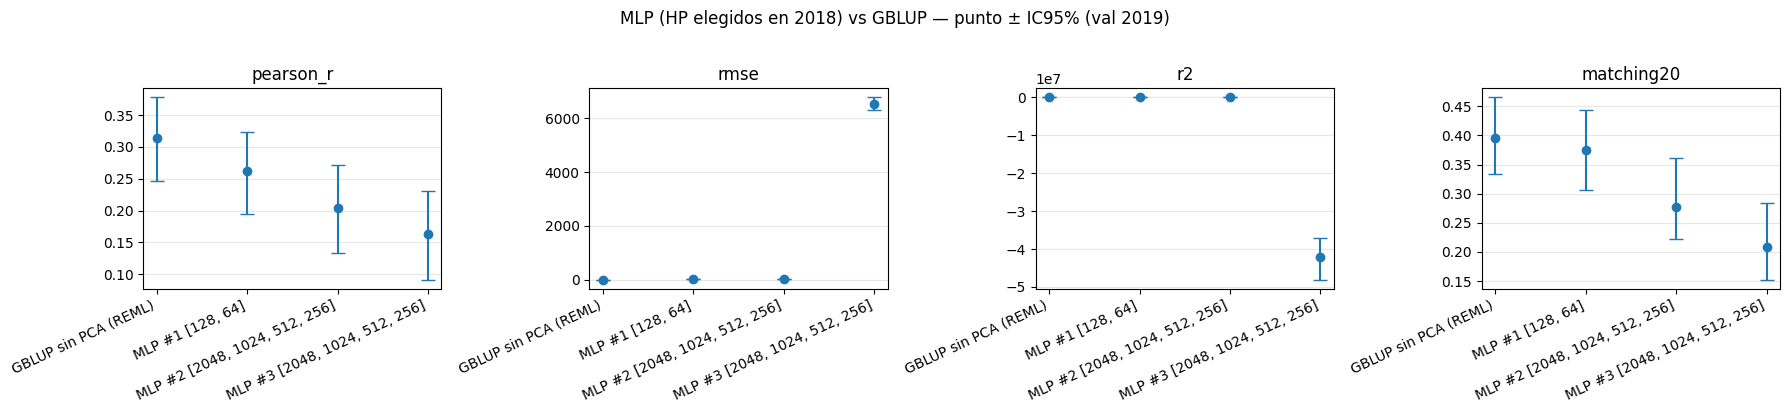

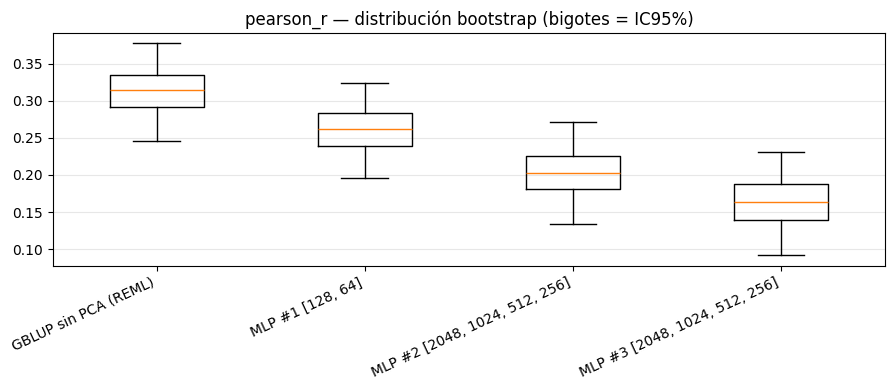

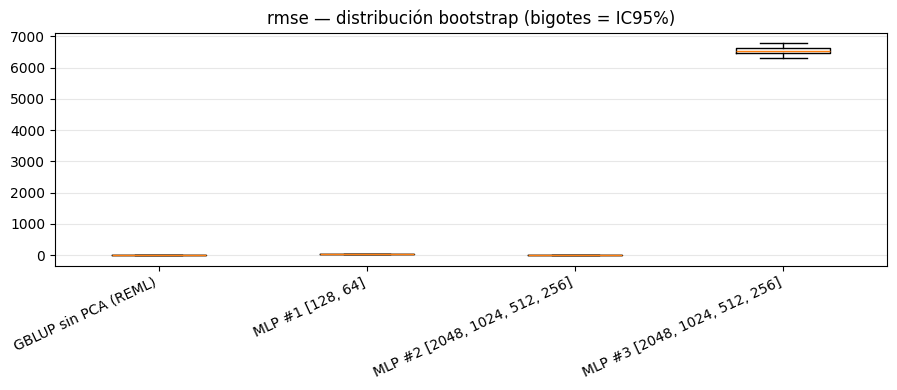

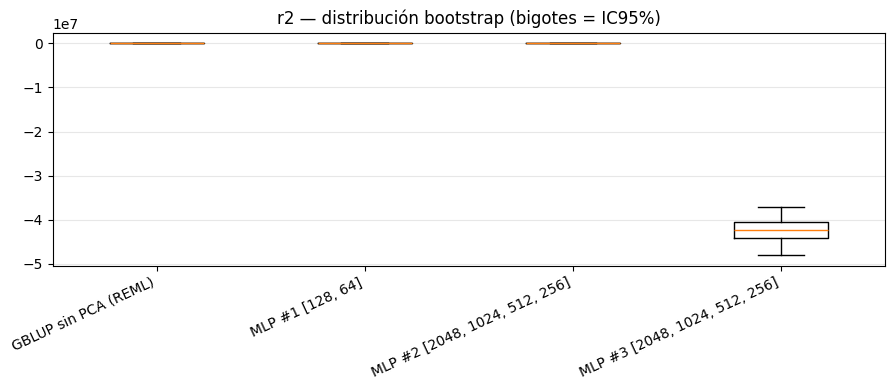

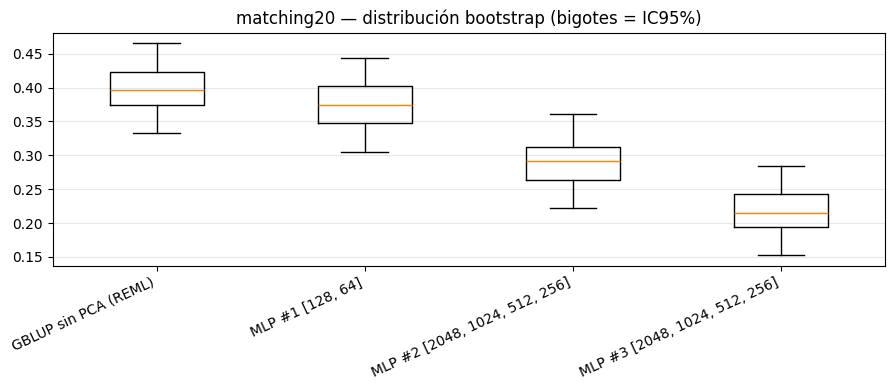

In [32]:
# 1. Gráfico de barras de error (Punto central ± IC95%)
fig = plot_ci(mlp_df, title="MLP (HP elegidos en 2018) vs GBLUP — punto ± IC95% (val 2019)")
fig.savefig(FIG_DIR / "ci_errorbars_mlp.png", dpi=150, bbox_inches="tight")
plt.show()

# 2. Boxplots de la distribución de bootstrap por métrica evaluada
for m in METRICS:
    fig = plot_box(mlp_samples, m)
    if fig is not None:
        fig.savefig(FIG_DIR / f"box_mlp_{m}.png", dpi=150, bbox_inches="tight")
        plt.show()

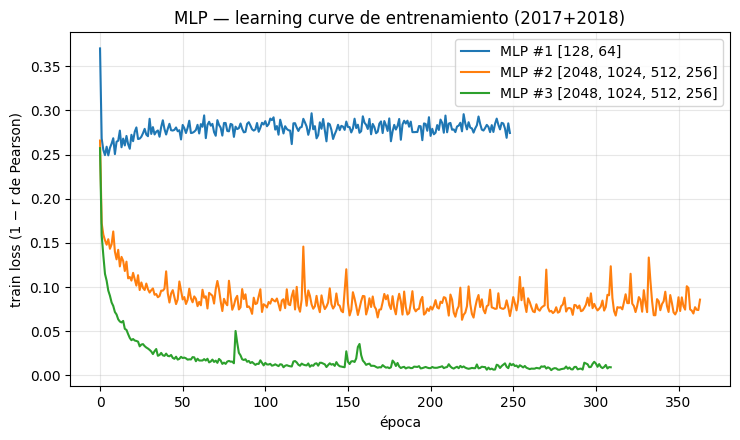

In [33]:
# Learning curves de los 3 MLP (train_loss = 1 − r de Pearson por época). Con
# patience=null no hay inner-val, así que solo hay curva de TRAIN: la de val por época
# aparece en wandb únicamente cuando hay early stopping (>=2 años de train; ver bitácora).
# Se ven desde history_, que run_evaluation devuelve y cachea (CURVES_BY_MODEL).
fig, ax = plt.subplots(figsize=(7.5, 4.5))
plotted = 0
for name in MLP_CONFIGS:
    if name == "GBLUP sin PCA (REML)":
        continue
    curves = CURVES_BY_MODEL.get(name) or []
    if not curves:
        continue
    hist = curves[0]["history"]                 # split fijo: un único fold
    ax.plot([h["epoch"] for h in hist], [h["train_loss"] for h in hist], lw=1.5, label=name)
    plotted += 1
if plotted:
    ax.set_xlabel("época"); ax.set_ylabel("train loss (1 − r de Pearson)")
    ax.set_title("MLP — learning curve de entrenamiento (2017+2018)")
    ax.legend(); ax.grid(True, alpha=0.3)
    fig.tight_layout()
    fig.savefig(FIG_DIR / "mlp_learning_curves.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    plt.close(fig)
    print("(sin curvas: corré la celda de evaluación del MLP en un entorno con torch, p.ej. WSL)")

### Lectura

**Selección (val 2018).** Los 3 mejores del sweep fueron `[128, 64]` (Pearson 0.418),
`[2048, 1024, 512, 256]` (0.402) y otra `[2048, 1024, 512, 256]` (0.389) — todas con
`leaky_relu`/`relu`, sin batchnorm y `max_epochs` ≈ 250–360. Ojo: 2018 es la cohorte más
ruidosa del dev, así que esos valores son la señal de selección, no el veredicto.

**Reporte (val 2019).** El veredicto honesto sale de reentrenar 2017+2018 y testear en
2019 (tabla, gráficos y test pareado de arriba). Como con XGBoost, esperá que el Pearson
de 2019 **baje** respecto al de 2018 (winner's curse evitado: 2019 no entró en la
selección). La pregunta es si el MLP con loss Pearson **le gana o empata a GBLUP**
(0.314) en la portada — algo que ni XGBoost ni el AE lograron. El test pareado dice si la
diferencia es significativa (IC95% de la resta que no cruza 0).

**RMSE / R².** Con loss = Pearson la red **no calibra escala**, así que su RMSE/R² no son
informativos (no los compares como con los otros modelos); el Pearson y el matching20 sí
lo son. 2020 sigue sellado.

## matching20 — coincidencia del top-20% (utilidad para seleccionar)

En selección genómica lo que importa no es solo la correlación global, sino **acertar a
qué líneas conviene avanzar**. El **matching20** (coincidence index al 20%) mide eso:

1. Ordenás las líneas de validación (2019) por **GY observado** y tomás el **mejor 20%**
   (las que de verdad rindieron más).
2. Ordenás las mismas líneas por **GY predicho** y tomás su **mejor 20%**.
3. `matching20 = |top_obs ∩ top_pred| / k`, con `k = round(0.2·n)`. El conteo "a cuántas
   les pegó" = `matching20 · k`.

**¿Está bien así?** Sí — es el *coincidence index* estándar (selección truncada) en
mejoramiento genómico. Dos aclaraciones importantes:

- Se evalúa sobre **líneas/genotipos** (las observaciones de 2019), **no sobre "genes"**
  ni marcadores: el modelo predice un fenotipo (GY) por línea, así que el "top" son las
  líneas candidatas a selección.
- **Referencia al azar ≈ 0.20**: elegir un 20% al azar ya acierta ~20% del top real, así
  que un modelo útil tiene que estar **por encima de 0.20** (1.0 = recupera exactamente
  el top observado). Asume "más GY = mejor" (`higher_is_better=True`).

La métrica está centralizada en `src/eval/metrics.py:coincidence_index` y se calcula por
fold en `run_evaluation` (con su IC por el mismo bootstrap cluster a nivel línea), así
que aplica a **todos** los modelos sin recomputar nada a mano.

In [34]:
# === matching20 para TODOS los modelos evaluados (consolidado) =====================
# Junta los DataFrames de cada sección que hayas corrido (PCA-sweep, AE-d, XGBoost, MLP)
# y arma una tabla única de matching20 con su IC y el conteo "a cuántas líneas les pegó"
# (= matching20 * k, con k = top-20% de n_val). Deduplica el baseline GBLUP repetido.
_dfs = [g for g in (globals().get(nm) for nm in ["df", "dim_df", "xgb_df", "mlp_df"]) if g is not None]
big = pd.concat(_dfs, ignore_index=True)
match = big[big.metric == "matching20"].drop_duplicates("model").reset_index(drop=True)
match["k_top20"] = (0.2 * match["n"]).round().astype(int)
match["aciertos"] = (match["point"] * match["k_top20"]).round().astype("Int64")  # nan-safe
match = match[["model", "n", "k_top20", "aciertos", "point", "lo", "hi"]].rename(
    columns={"model": "modelo", "n": "n_val", "point": "matching20", "lo": "IC_lo", "hi": "IC_hi"})
match = match.sort_values("matching20", ascending=False).reset_index(drop=True)
print("matching20 (top-20% de val 2019). Azar ~0.20; 'aciertos' = líneas del top-20% real "
      "que el modelo recuperó (de k).")
match

matching20 (top-20% de val 2019). Azar ~0.20; 'aciertos' = líneas del top-20% real que el modelo recuperó (de k).


,modelo,n_val,k_top20,aciertos,matching20,IC_lo,IC_hi
0,PCA-1000 (elegida en 2019),722,144,60,0.416667,0.340278,0.472222
1,GBLUP sin PCA (REML),722,144,57,0.395833,0.333333,0.465278
2,PCA-256,722,144,55,0.381944,0.312500,0.451389
3,"MLP #1 [128, 64]",722,144,54,0.375000,0.305556,0.444444
4,AE-256 + GBLUP,722,144,51,0.354167,0.277778,0.409722
5,XGB AE-256,722,144,49,0.340278,0.263889,0.402778
6,AE-128 + GBLUP,722,144,49,0.340278,0.277778,0.409722
7,PCA-128 (elegida en 2018),722,144,46,0.319444,0.250000,0.388889
8,XGB PCA-128,722,144,46,0.319444,0.250000,0.402778
9,PCA-128,722,144,46,0.319444,0.250000,0.388889


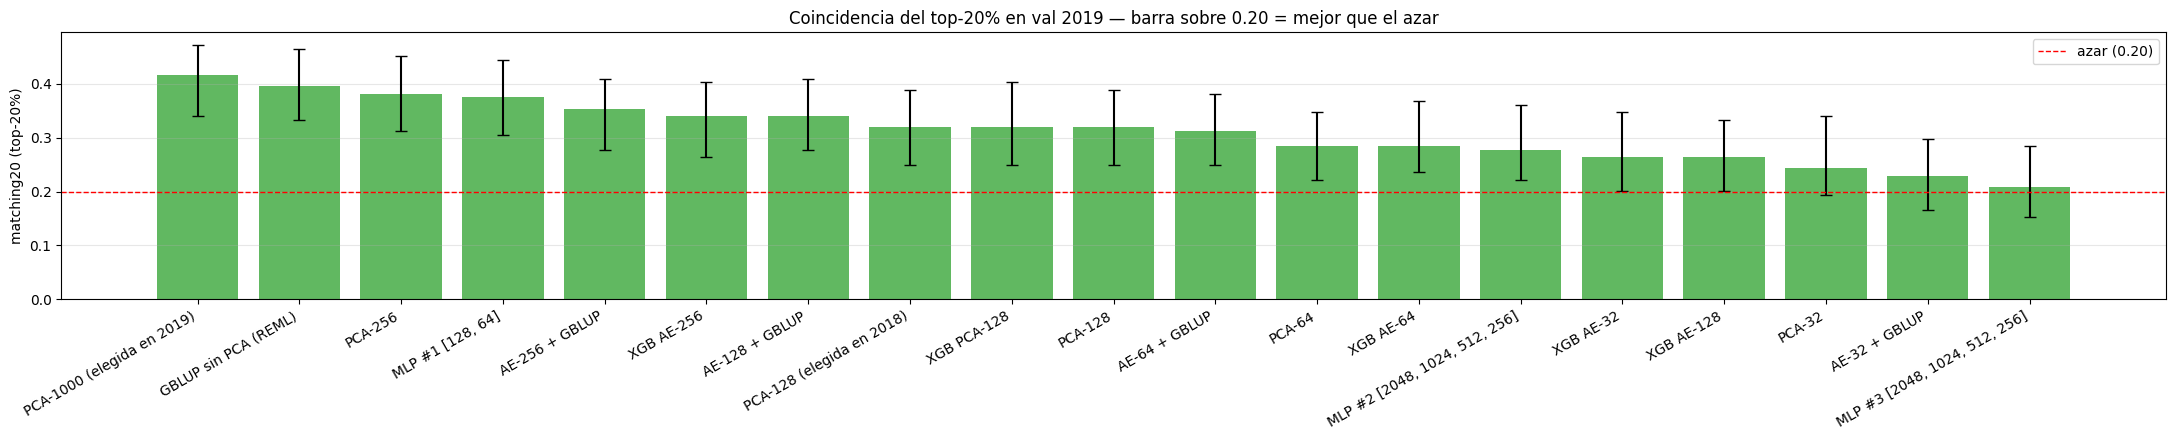

In [35]:
# Barras de matching20 por modelo (con IC95%) y la línea del azar (0.20): barra por
# encima de la roja = el modelo selecciona el top-20% mejor que tirar la moneda.
order = match.sort_values("matching20", ascending=False).reset_index(drop=True)
x = np.arange(len(order))
yerr = np.vstack([np.maximum(order["matching20"] - order["IC_lo"], 0),
                  np.maximum(order["IC_hi"] - order["matching20"], 0)])
fig, ax = plt.subplots(figsize=(1.0 * len(order) + 3, 4.5))
ax.bar(x, order["matching20"], color="tab:green", alpha=0.75)
ax.errorbar(x, order["matching20"], yerr=yerr, fmt="none", ecolor="black", capsize=4)
ax.axhline(0.20, color="red", ls="--", lw=1, label="azar (0.20)")
ax.set_xticks(x); ax.set_xticklabels(order["modelo"], rotation=30, ha="right")
ax.set_ylabel("matching20 (top-20%)")
ax.set_title("Coincidencia del top-20% en val 2019 — barra sobre 0.20 = mejor que el azar")
ax.legend(); ax.grid(True, axis="y", alpha=0.3)
fig.tight_layout(); fig.savefig(FIG_DIR / "matching20_all.png", dpi=150, bbox_inches="tight")
plt.show()

## Fase A — ensembles y pérdidas (cada sección corre sola)

Compara, con el **mismo lenguaje visual** que las secciones de arriba (tabla + errorbar ± IC95%
+ boxplots por métrica + diferencia pareada vs el baseline), estas extensiones sobre GBLUP:

- **A1 — Drought**: MLP (sweep propio) vs GBLUP, GY en sequía.
- **A2 — Pérdida `pearson_mse`**: mejor `mse_weight` (elegido en 2018) reentrenado y reportado en 2019 vs GBLUP.
- **A4 — Ensemble de redes** (optimal y drought): promedio top-K y multi-seed vs GBLUP.

> Se quitó el ex-**A3** (blend MLP+GBLUP): el peso α se elige en 2018, pero como el MLP se
> selecciona del sweep *por* su Pearson en 2018, ese Pearson queda inflado (winner's curse) y la
> selección da α=1 (todo MLP), que en 2019 rinde peor que GBLUP. No hay un set limpio para elegir α
> en este esquema temporal (2019 es el reporte, 2020 sellado), así que el blend honesto no aporta.

**Cómo correr una sola sección (sin re-ejecutar todo).** Tras reiniciar el kernel, corré **solo**
la celda *“Fase A · setup”* de abajo y después la sección que quieras: el setup importa todo de
`src/` y define los helpers, y cada evaluación levanta el resultado del **caché en disco**
(`outputs/eval_cache`) ⇒ *cache hit*, sin reentrenar. La primera vez que aparece una config nueva sí
entrena una vez y la cachea. Toda la lógica vive en `src/eval/` (`ensemble.py`, `report_plots.py`,
`nb_eval.py`).


In [8]:
# === Fase A · setup — CORRÉ ESTO PRIMERO (rápido: imports + helpers, no reentrena) ========
# Único prerequisito de A1/A2/A4: con esto corrido, cada sección corre por separado.
# La evaluación usa el caché en disco (outputs/eval_cache) => cache hit = sin reentrenar.
import os, sys, pathlib, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Pararse en la raíz del repo (donde vive src/) por si corrés la Fase A sin las celdas de arriba.
ROOT = pathlib.Path.cwd()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.utils.config import load_config, set_nested
from src.training.sweep import best_run_from_sweep, top_runs_from_sweep
from src.eval.metrics import pearson_r, rmse, r2, coincidence_index
from src.eval.ensemble import (
    align_by_line, average_predictions, bootstrap_table, paired_diff_summary,
)
from src.eval.report_plots import plot_ci, plot_box, plot_paired_diff, plot_metric_vs_param
from src.eval.nb_eval import make_evaluators

# Constantes (con fallback por si no corriste las celdas de arriba).
METRICS    = globals().get("METRICS", ("pearson_r", "rmse", "r2", "matching20"))
N_BOOT     = globals().get("N_BOOT", 2000)
ALPHA      = globals().get("ALPHA", 0.05)
USE_CACHE  = globals().get("USE_CACHE", True)
FIG_DIR    = globals().get("FIG_DIR", ROOT / "experiments" / "figs"); FIG_DIR.mkdir(parents=True, exist_ok=True)
MLP_SWEEP  = globals().get("MLP_SWEEP", "oromagnoli-/maze-genomic-pred/kyl04lf5")
MLP_BASE   = globals().get("MLP_BASE",  "configs/exp_mlp_2017_to_2018.yaml")
GBLUP_2019 = "configs/exp_gblup_2017_2018_to_2019.yaml"   # baseline reporte (val 2019)
GBLUP_2018 = "configs/exp_gblup_2017_to_2018.yaml"        # baseline inner-val (val 2018)
REPORT_CV  = globals().get("REPORT_CV", {"scheme": "fixed_temporal", "val_year": 2019,
             "train_years": [2017, 2018], "holdout_test_year": 2020, "enforce_disjoint_lines": True})

# Métricas (callable) para los IC pareados de los ensembles (matching20 = coincidence top-20%).
ENS_METRICS = {"pearson_r": pearson_r, "rmse": rmse, "r2": r2,
               "matching20": lambda yt, yp: coincidence_index(yt, yp, 0.2)}

# Evaluadores cacheados (no tocan wandb). CURVES/PREDS se preservan entre secciones (se reusan
# si ya existen). make_evaluators arma evaluate_model (rows+samples del bootstrap) y
# eval_with_preds (además stashea las predicciones del fold de val para los ensembles).
CURVES_BY_MODEL = globals().get("CURVES_BY_MODEL", {})
PREDS_BY_MODEL  = globals().get("PREDS_BY_MODEL", {})
evaluate_model, eval_with_preds, CURVES_BY_MODEL, PREDS_BY_MODEL = make_evaluators(
    METRICS, n_boot=N_BOOT, alpha=ALPHA, use_cache=USE_CACHE,
    curves_by_model=CURVES_BY_MODEL, preds_by_model=PREDS_BY_MODEL)


def apply_overrides(base, overrides):
    """Config = base + HP del sweep (mantiene el cv del base, sin guardar artifact)."""
    cfg = load_config(base)
    for k, v in overrides.items():
        set_nested(cfg, k, v)
    cfg["artifacts"] = {"save_model": False}
    return cfg


def report_config(base, overrides):
    """Como apply_overrides pero con el cv de REPORTE (reentrena 2017+2018 -> testea 2019)."""
    cfg = apply_overrides(base, overrides)
    cfg["cv"] = dict(REPORT_CV)
    return cfg


def save_show(fig, fname):
    """Guarda la figura en FIG_DIR y la muestra (no-op si fig es None)."""
    if fig is not None:
        fig.savefig(FIG_DIR / fname, dpi=150, bbox_inches="tight")
        plt.show()


def print_paired(summary, *, title=None):
    """Imprime paired_diff_summary: + favorece al modelo salvo en rmse; * = IC95% no cruza 0."""
    if title:
        print(title)
    for name, per in summary.items():
        print(f"  {name}:")
        for m, d in per.items():
            star = "  *" if d["sig"] else ""
            print(f"    {m:10s}: delta={d['delta']:+.3f}  IC95%[{d['lo']:+.3f}, {d['hi']:+.3f}]{star}")



## A1 — Drought: MLP (sweep propio) vs GBLUP (GY en sequía)

Mismo protocolo honesto que *optimal* pero `data.env: drought` y con **sweep propio**
(`MLP_SWEEP_DROUGHT`). Reentrenamos las **top-3** redes (2017+2018 → 2019) y las comparamos
contra **GBLUP drought** con la misma batería que arriba: tabla, errorbar ± IC95%, **boxplots por
métrica de los 4 modelos** y la **diferencia pareada** (MLP − GBLUP, caja que no cruza 0 ⇒
significativa). Bootstrap cluster a nivel línea, seed 575. 2020 sellado.

> **Lectura de métricas.** El MLP usa `loss=pearson` (escala no calibrada) ⇒ su RMSE/R² no es
> informativo; mirá **Pearson** (portada) y **matching20** (utilidad para seleccionar el top-20%).
> Que MLP #1 y #3 superen a GBLUP en Pearson y #3 destaque en matching20 es buena señal — la
> significancia la confirma la **diferencia pareada** (que el IC95% de MLP − GBLUP no cruce 0).


[ok] GBLUP drought


wandb: [wandb.Api()] Loaded credentials for https://api.wandb.ai from C:\Users\MODDE\.netrc.


[ok] MLP drought #1 (run inq18xmv): pearson(val2018)=0.258
[ok] MLP drought #2 (run 7g404pxo): pearson(val2018)=0.256
[ok] MLP drought #3 (run z5skcsej): pearson(val2018)=0.252

GY en sequía, val 2019 (Pearson = portada):


metric,pearson_r,rmse,r2,matching20
model,,,,
GBLUP drought,0.2413,1.1873,-0.5286,0.3542
MLP drought #1,0.2619,1.1994,-0.5597,0.3333
MLP drought #2,0.1814,2.1726,-4.1184,0.2847
MLP drought #3,0.2613,1.3252,-0.9041,0.3750


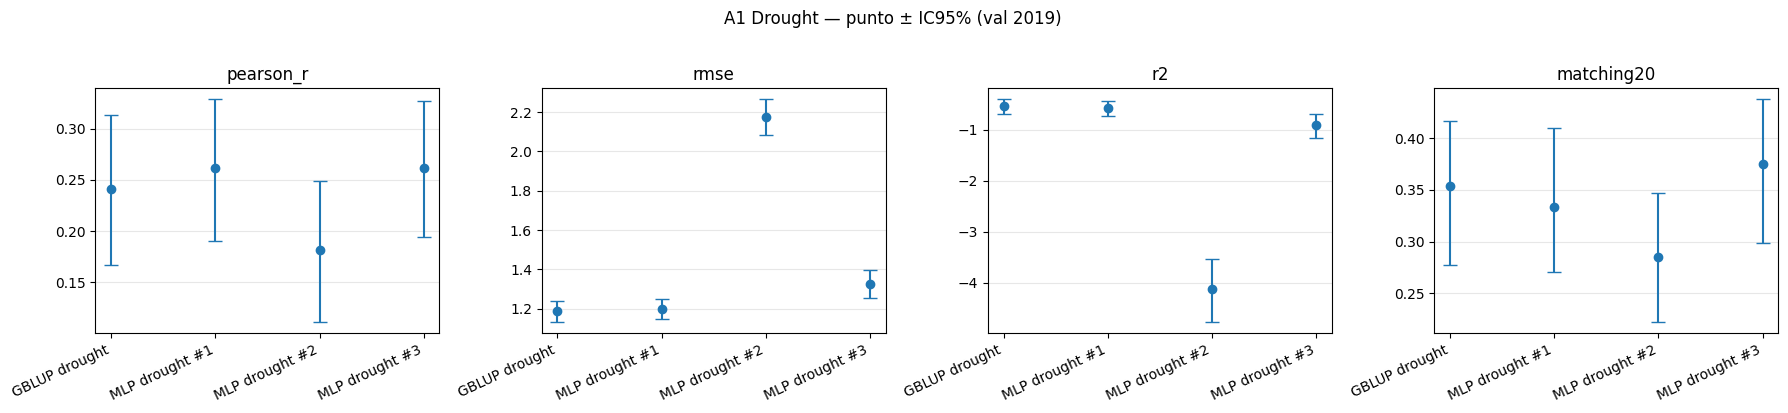

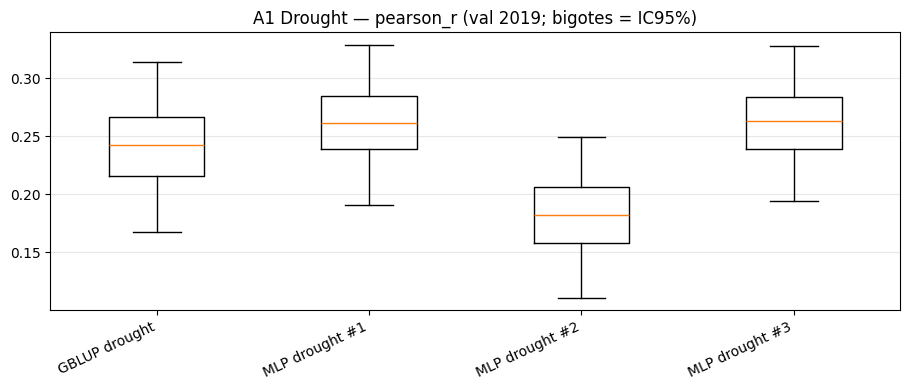

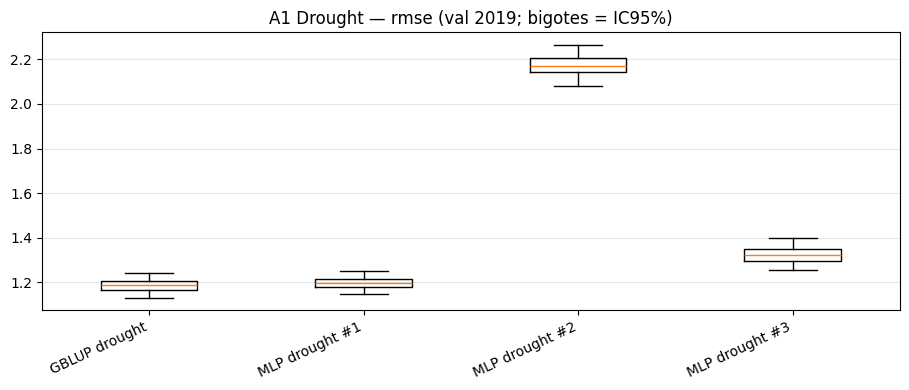

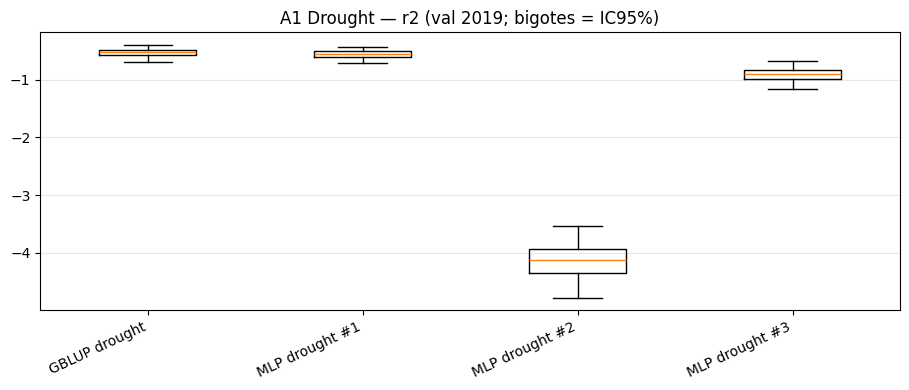

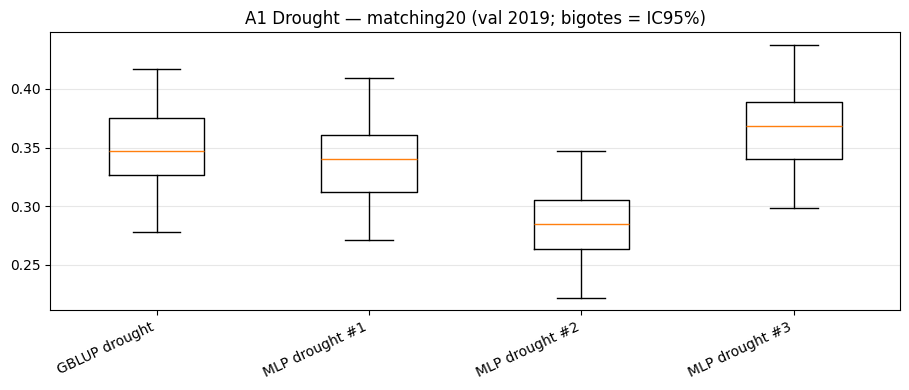

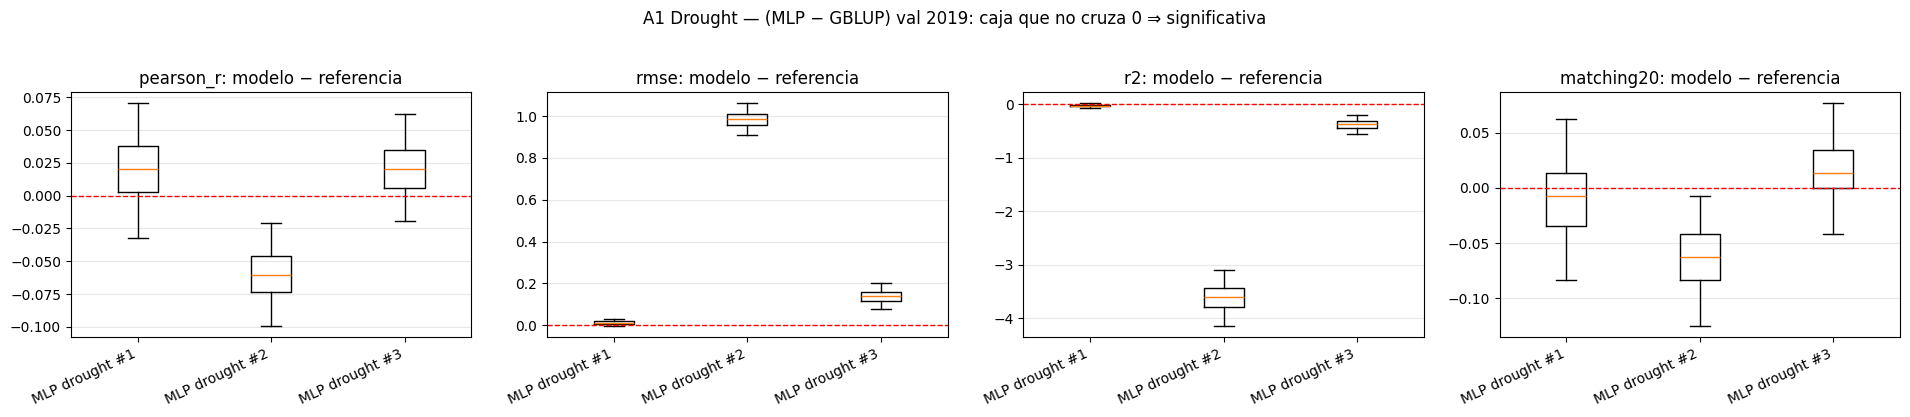


Diferencia pareada vs GBLUP drought (val 2019; * = IC95% no cruza 0):
  MLP drought #1:
    pearson_r : delta=+0.020  IC95%[-0.032, +0.070]
    rmse      : delta=+0.012  IC95%[-0.004, +0.029]
    r2        : delta=-0.032  IC95%[-0.076, +0.010]
    matching20: delta=-0.010  IC95%[-0.083, +0.062]
  MLP drought #2:
    pearson_r : delta=-0.060  IC95%[-0.099, -0.021]  *
    rmse      : delta=+0.986  IC95%[+0.910, +1.060]  *
    r2        : delta=-3.609  IC95%[-4.148, -3.100]  *
    matching20: delta=-0.065  IC95%[-0.125, -0.007]  *
  MLP drought #3:
    pearson_r : delta=+0.021  IC95%[-0.019, +0.062]
    rmse      : delta=+0.138  IC95%[+0.077, +0.200]  *
    r2        : delta=-0.378  IC95%[-0.566, -0.207]  *
    matching20: delta=+0.016  IC95%[-0.042, +0.076]


In [3]:
# === A1: Drought — MLP top-3 vs GBLUP, GY en sequía =======================================
# Requiere haber corrido la celda "Fase A · setup".
MLP_SWEEP_DROUGHT = "oromagnoli-/maze-genomic-pred/tt24pyzx"
MLP_BASE_DROUGHT  = "configs/exp_mlp_2017_to_2018_drought.yaml"
GBLUP_DROUGHT     = "configs/exp_gblup_2017_2018_to_2019_drought.yaml"
DR_REF = "GBLUP drought"

dr_rows, dr_samples = [], {}
r, s = evaluate_model(DR_REF, GBLUP_DROUGHT); dr_rows += r; dr_samples[DR_REF] = s
print(f"[ok] {DR_REF}")
for rank, (ov, p2018, rid) in enumerate(top_runs_from_sweep(MLP_SWEEP_DROUGHT, k=3), start=1):
    name = f"MLP drought #{rank}"
    r, s = evaluate_model(name, report_config(MLP_BASE_DROUGHT, ov))
    dr_rows += r; dr_samples[name] = s
    print(f"[ok] {name} (run {rid}): pearson(val2018)={p2018:.3f}")

dr_df = pd.DataFrame(dr_rows)
print("\nGY en sequía, val 2019 (Pearson = portada):")
display(dr_df.pivot(index="model", columns="metric", values="point")[list(METRICS)].round(4))

save_show(plot_ci(dr_df, title="A1 Drought — punto ± IC95% (val 2019)"), "a1_ci.png")
for m in METRICS:                                   # boxplots por métrica de los 4 modelos
    save_show(plot_box(dr_samples, m, title=f"A1 Drought — {m} (val 2019; bigotes = IC95%)"),
              f"a1_box_{m}.png")
save_show(plot_paired_diff(dr_samples, ref=DR_REF, metrics=METRICS,
                           title="A1 Drought — (MLP − GBLUP) val 2019: caja que no cruza 0 ⇒ significativa"),
          "a1_paired_diff.png")
print_paired(paired_diff_summary(dr_samples, DR_REF, METRICS, alpha=ALPHA),
             title="\nDiferencia pareada vs GBLUP drought (val 2019; * = IC95% no cruza 0):")


## A2 — Pérdida `pearson_mse`: mejor `mse_weight` (sweep 2018) → reporte en 2019 vs GBLUP

Con `loss=pearson` la red no calibra escala (RMSE/R² no informativos). `pearson_mse` suma
`mse_weight·MSE` (sobre el target estandarizado): mantiene el ranking del término Pearson y
**ancla la escala**, así RMSE/R² vuelven a ser informativos.

Protocolo honesto (igual que el resto): el `mse_weight` se **elige por `pearson_r_mean` en val
2018** (tu sweep grid `uu24v5as` sobre `exp_mlp_pearson_mse_2017_to_2018.yaml`) y se **reporta
reentrenando 2017+2018 y evaluando en 2019**. Mostramos los **3 mejores** `mse_weight` del sweep,
reentrenados a 2019, contra **GBLUP**: tabla, métrica vs `mse_weight`, errorbar ± IC95%, boxplots y
diferencia pareada. Como pearson_mse calibra, en 2019 el RMSE/R² **sí** son comparables con GBLUP.
La pregunta: ¿el mejor `mse_weight` mantiene el Pearson de GBLUP **y** le iguala la calibración?
2020 sellado.

> El sweep maximiza Pearson y subir `mse_weight` solo puede bajarlo, así que el mejor tiende a ser
> el peso más chico (~0.1). Antes el notebook mostraba esto en 2018 y barría pesos a mano; ahora
> sale del sweep y se reporta en 2019, como corresponde.


Selección en val 2018 — 3 mejores mse_weight del sweep (pearson_r_mean):
  mse_weight=0.1: pearson(2018)=0.3633  (run mijyv0sn)
  mse_weight=0.4: pearson(2018)=0.3374  (run k5waz53z)
  mse_weight=0.7: pearson(2018)=0.3340  (run ura9xjgk)
=> mejor mse_weight (2018) = 0.1. Reporte: reentreno 2017+2018 y evalúo en 2019.

[ok] pearson_mse w=0.1 (best)
[ok] pearson_mse w=0.4
[ok] pearson_mse w=0.7

Reporte en val 2019 (reentrenado 2017+2018; Pearson = portada; RMSE/R2 informativos: pearson_mse calibra):


metric,pearson_r,rmse,r2,matching20
model,,,,
GBLUP,0.3145,1.3016,-0.6644,0.3958
pearson_mse w=0.1 (best),0.2058,1.4541,-1.0771,0.3125
pearson_mse w=0.4,0.2586,1.2057,-0.4280,0.2708
pearson_mse w=0.7,0.2421,1.2168,-0.4546,0.2639


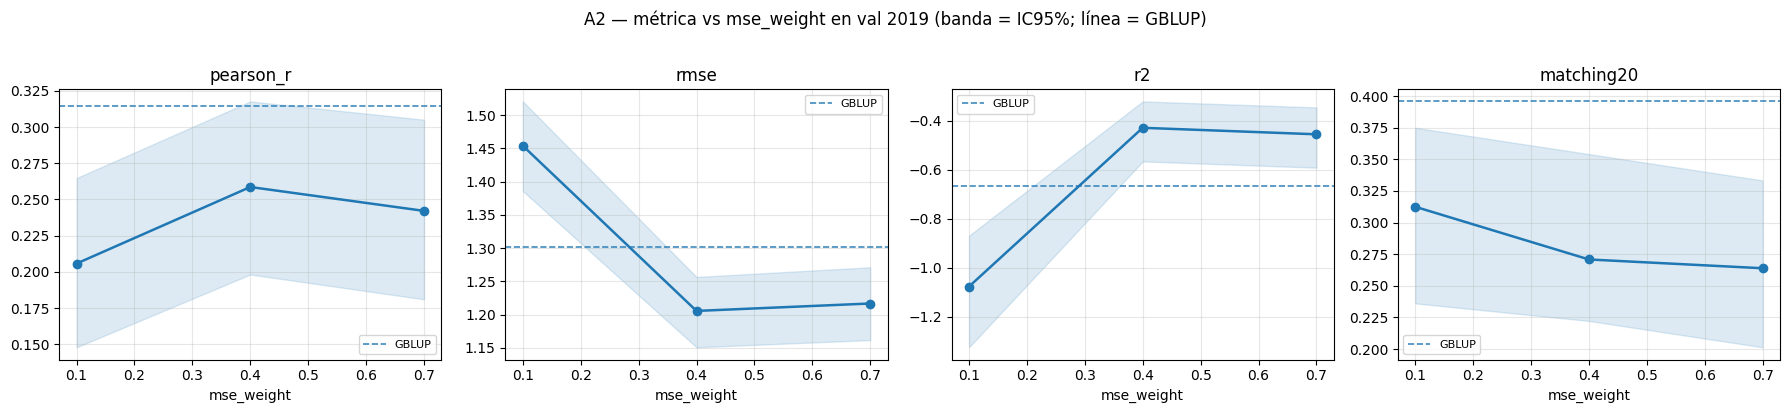

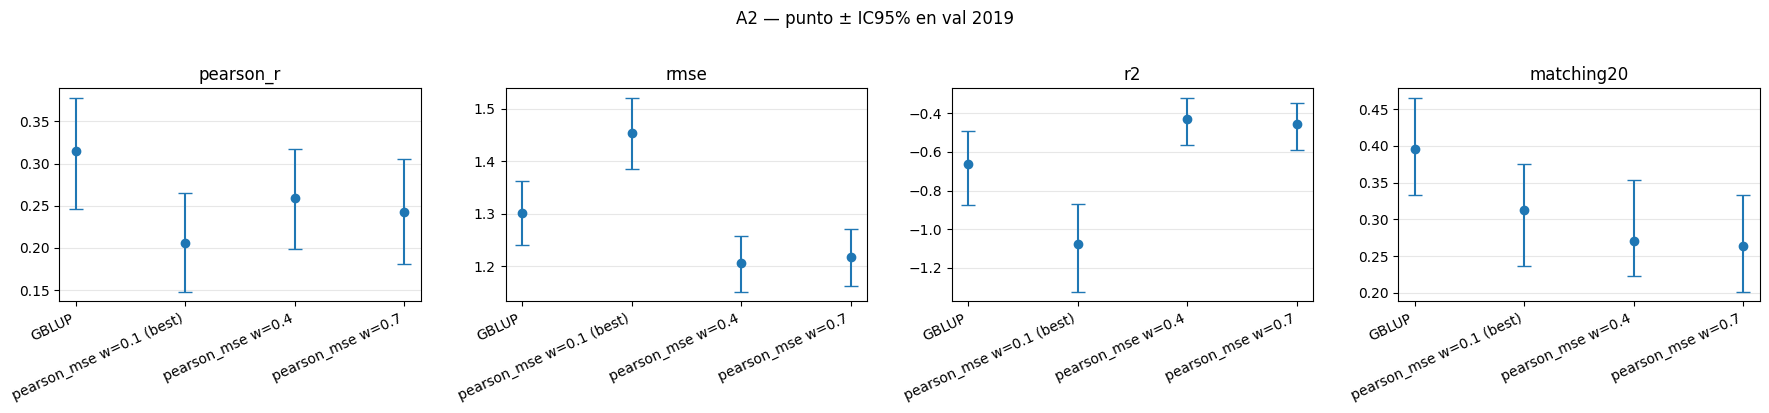

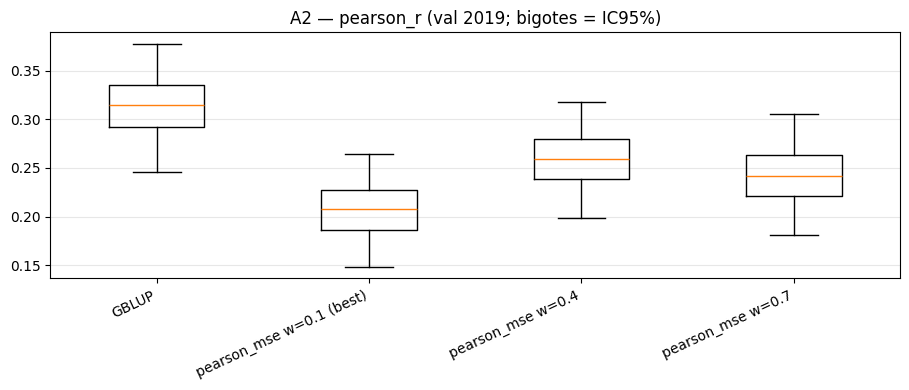

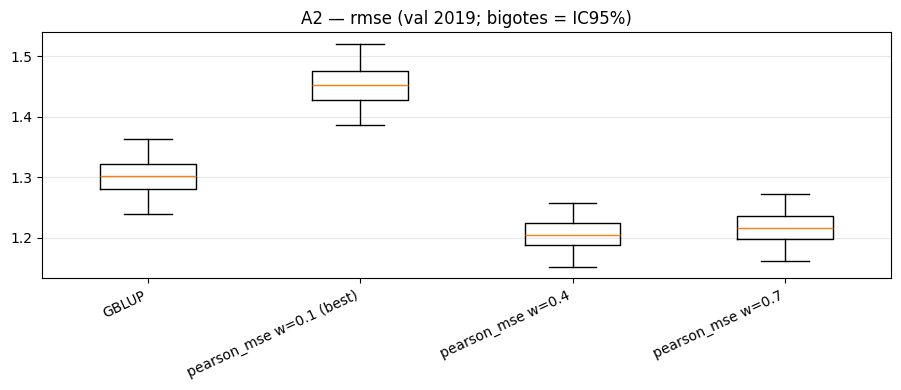

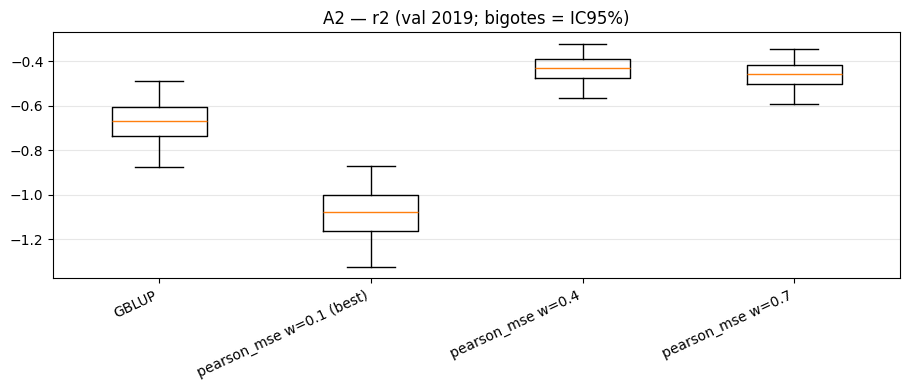

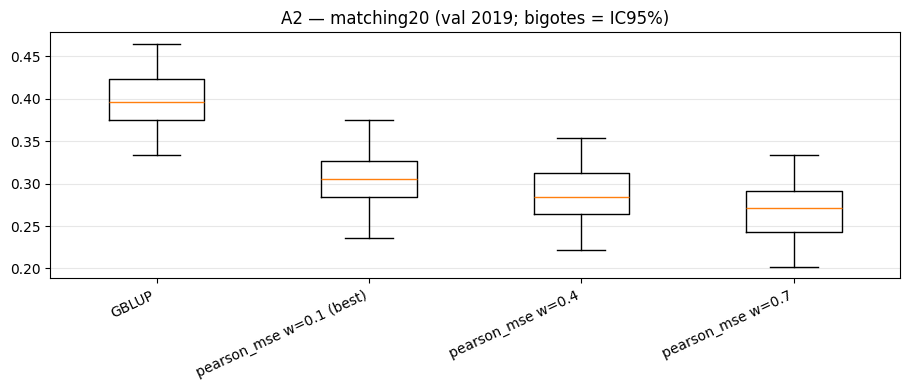

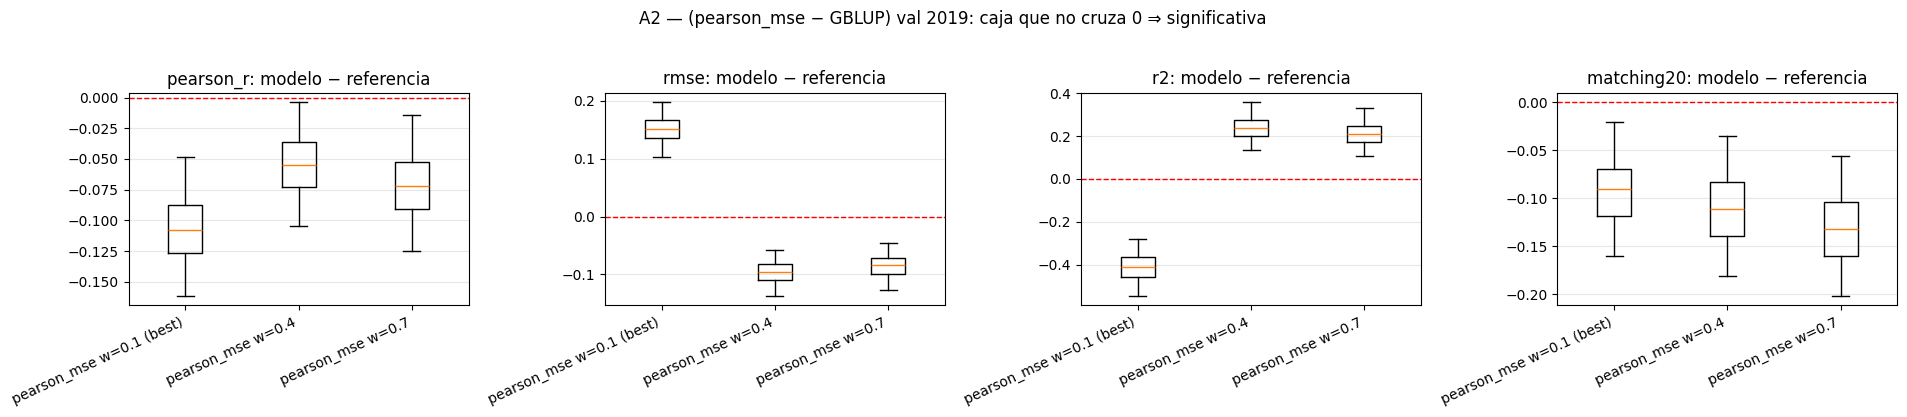


Diferencia pareada vs GBLUP (val 2019; * = IC95% no cruza 0):
  pearson_mse w=0.1 (best):
    pearson_r : delta=-0.107  IC95%[-0.161, -0.049]  *
    rmse      : delta=+0.151  IC95%[+0.103, +0.197]  *
    r2        : delta=-0.411  IC95%[-0.545, -0.279]  *
    matching20: delta=-0.092  IC95%[-0.160, -0.021]  *
  pearson_mse w=0.4:
    pearson_r : delta=-0.055  IC95%[-0.105, -0.004]  *
    rmse      : delta=-0.096  IC95%[-0.137, -0.058]  *
    r2        : delta=+0.239  IC95%[+0.137, +0.358]  *
    matching20: delta=-0.110  IC95%[-0.181, -0.035]  *
  pearson_mse w=0.7:
    pearson_r : delta=-0.071  IC95%[-0.125, -0.014]  *
    rmse      : delta=-0.085  IC95%[-0.127, -0.045]  *
    r2        : delta=+0.212  IC95%[+0.108, +0.332]  *
    matching20: delta=-0.130  IC95%[-0.202, -0.056]  *


In [17]:
# === A2: pearson_mse — selección en 2018 (sweep) -> REPORTE en 2019 vs GBLUP ==============
# Requiere haber corrido la celda "Fase A · setup".
# Protocolo honesto (igual que el resto): el mse_weight se ELIGE por pearson_r_mean en val 2018
# (tu sweep grid), y se REPORTA reentrenando 2017+2018 y evaluando en 2019. Como pearson_mse
# calibra la escala, en 2019 el RMSE/R² SÍ son informativos y comparables con GBLUP.
MSE_SWEEP = "oromagnoli-/maze-genomic-pred/uu24v5as"          # sweep de mse_weight (val 2018)
MSE_BASE  = "configs/exp_mlp_pearson_mse_2017_to_2018.yaml"   # base del sweep (mejores HP + loss=pearson_mse)

# (1) Selección honesta en 2018: los 3 mejores mse_weight del sweep (por pearson en val 2018).
top3 = top_runs_from_sweep(MSE_SWEEP, k=3)
print("Selección en val 2018 — 3 mejores mse_weight del sweep (pearson_r_mean):")
for ov, p2018, rid in top3:
    print(f"  mse_weight={float(ov['model.params.mse_weight']):g}: pearson(2018)={p2018:.4f}  (run {rid})")
best_w = float(top3[0][0]["model.params.mse_weight"])
print(f"=> mejor mse_weight (2018) = {best_w:g}. Reporte: reentreno 2017+2018 y evalúo en 2019.\n")

# (2) REPORTE en 2019: GBLUP + los 3 mejores mse_weight, reentrenados 2017+2018 -> 2019.
a2_rows, a2_samples, param_by_model = [], {}, {}
r, s = evaluate_model("GBLUP", GBLUP_2019); a2_rows += r; a2_samples["GBLUP"] = s
for ov, _, _ in top3:
    w = float(ov["model.params.mse_weight"])
    name = f"pearson_mse w={w:g}" + (" (best)" if w == best_w else "")
    r, s = evaluate_model(name, report_config(MSE_BASE, ov))
    a2_rows += r; a2_samples[name] = s; param_by_model[name] = w
    print(f"[ok] {name}")

a2_df = pd.DataFrame(a2_rows)
print("\nReporte en val 2019 (reentrenado 2017+2018; Pearson = portada; RMSE/R2 informativos: pearson_mse calibra):")
display(a2_df.pivot(index="model", columns="metric", values="point")[list(METRICS)].round(4))

# (a) métrica vs mse_weight en 2019, con GBLUP como línea de referencia por métrica.
ref_lines = {m: {"GBLUP": float(a2_df[(a2_df.model == "GBLUP") & (a2_df.metric == m)].point.iloc[0])}
             for m in METRICS}
save_show(plot_metric_vs_param(a2_df, param_by_model, ref_lines=ref_lines, xlabel="mse_weight",
                               title="A2 — métrica vs mse_weight en val 2019 (banda = IC95%; línea = GBLUP)"),
          "a2_metric_vs_mse_weight.png")
# (b) errorbar ± IC95% y (c) boxplots por métrica; (d) diferencia pareada vs GBLUP.
save_show(plot_ci(a2_df, title="A2 — punto ± IC95% en val 2019"), "a2_ci.png")
for m in METRICS:
    save_show(plot_box(a2_samples, m, title=f"A2 — {m} (val 2019; bigotes = IC95%)"), f"a2_box_{m}.png")
save_show(plot_paired_diff(a2_samples, ref="GBLUP", metrics=METRICS,
                           title="A2 — (pearson_mse − GBLUP) val 2019: caja que no cruza 0 ⇒ significativa"),
          "a2_paired_diff.png")
print_paired(paired_diff_summary(a2_samples, "GBLUP", METRICS, alpha=ALPHA),
             title="\nDiferencia pareada vs GBLUP (val 2019; * = IC95% no cruza 0):")


## A4 — Ensemble de redes (promedio) vs GBLUP

Dos formas de reducir varianza, evaluadas en 2019 con IC95% pareado vs GBLUP: **(a) top-K** —
promedio de ŷ de las 3 mejores redes del sweep; **(b) multi-seed** — la mejor red reentrenada con
varias `random_state` (init de torch distinto) y promediada. Comparamos contra la **mejor red sola**
y el **baseline GBLUP**: si el promedio baja varianza, su punto sube y/o su IC se angosta respecto
de la red sola. Todas las predicciones se alinean a la misma intersección de líneas (val 2019).

> **Escala (z-score).** Como en A3, el MLP (`loss=pearson`) tiene escala arbitraria, así que
> **promediamos y comparamos sobre z-scores** (`standardize=True`): si no, el modelo de mayor
> varianza domina el promedio y el "ensemble" colapsa a ese. `Pearson`/`matching20` son la portada
> (invariantes al z-score); el RMSE/R² queda en escala estandarizada (solo orientativo). 2020 sellado.


  [cache hit] MLP top#1 (77c60131156e720c)
  [cache hit] MLP seed575 (77c60131156e720c)
  [cache hit] GBLUP@2019 (90f1d6fe13802d36)
val 2019 (Pearson/matching20 = portada; RMSE/R2 en escala estandarizada, orientativo):


metric,pearson_r,rmse,r2,matching20
model,,,,
Ensemble multi-seed (5),0.2945,6.4806,-40.2589,0.3542
Ensemble top-3,0.2389,6.4893,-40.3691,0.3056
GBLUP,0.3145,6.4775,-40.2192,0.3958
MLP (mejor sola),0.2618,6.4857,-40.3236,0.3750


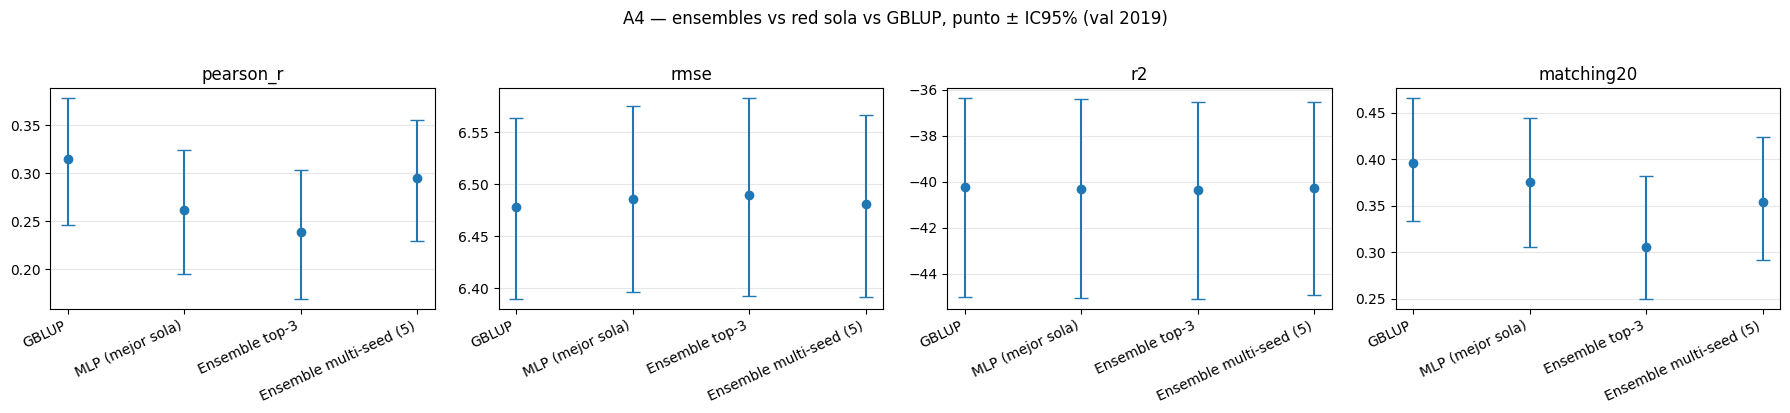

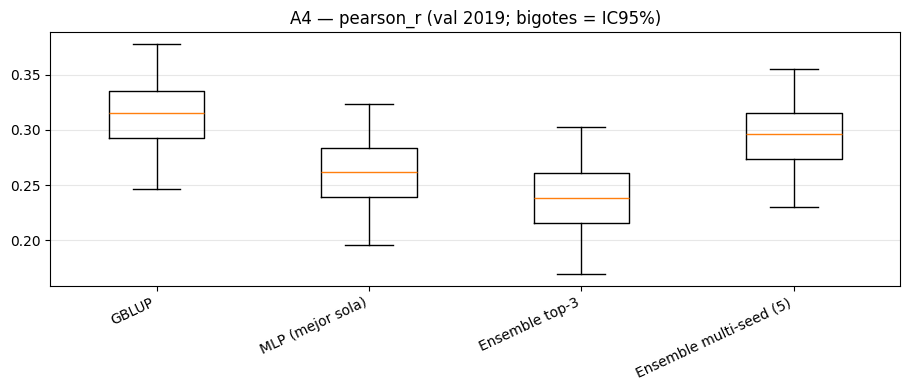

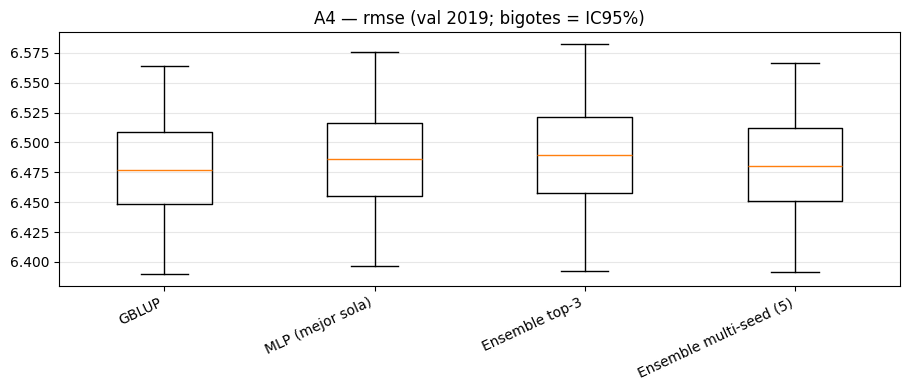

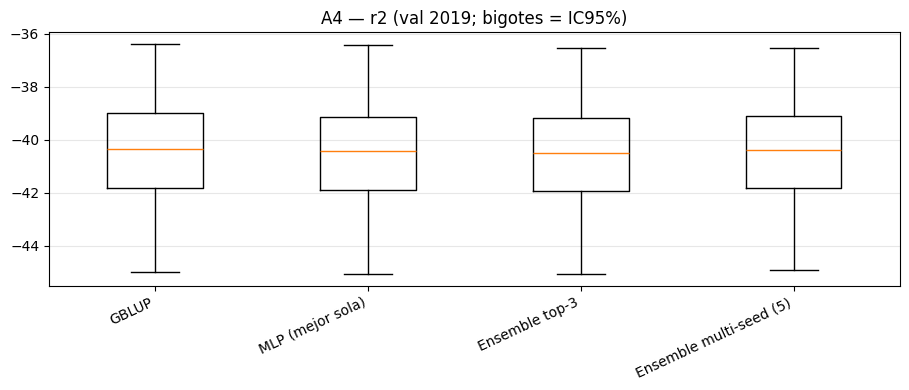

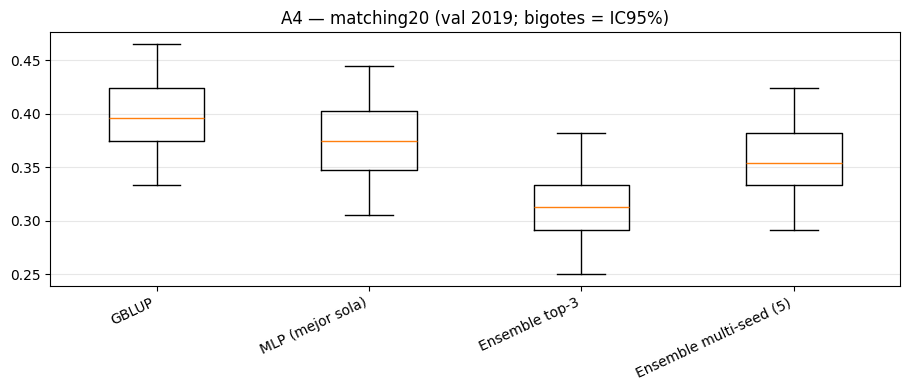

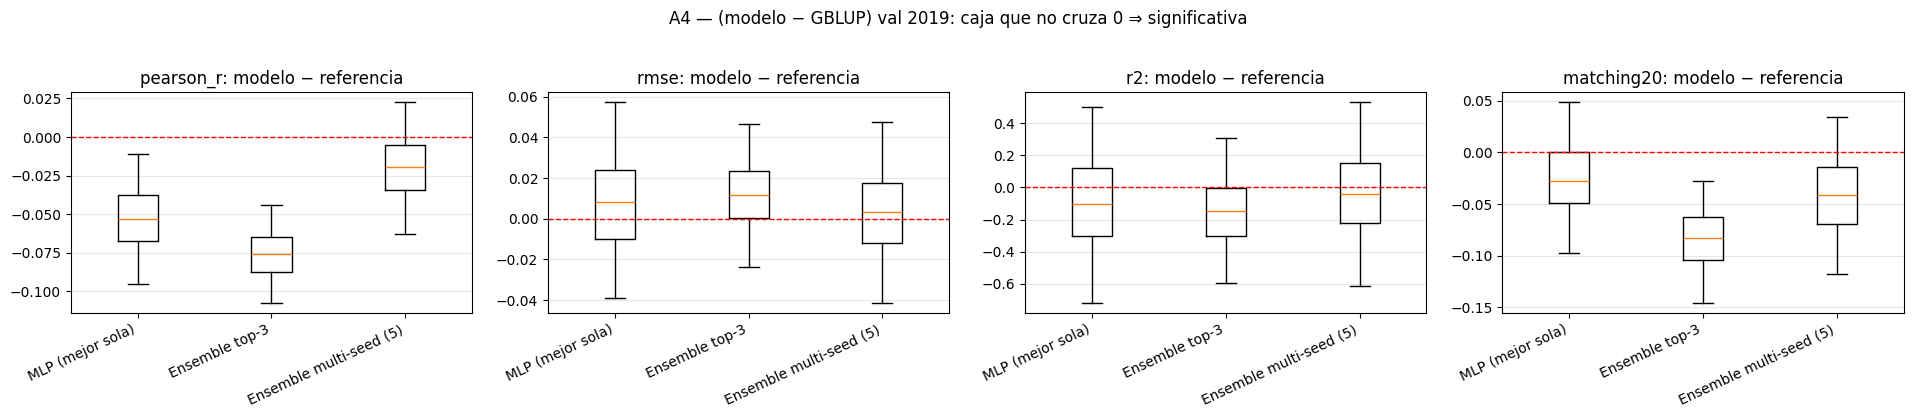


Diferencia pareada vs GBLUP (val 2019; * = IC95% no cruza 0):
  MLP (mejor sola):
    pearson_r : delta=-0.053  IC95%[-0.095, -0.011]  *
    rmse      : delta=+0.008  IC95%[-0.039, +0.057]
    r2        : delta=-0.098  IC95%[-0.718, +0.498]
    matching20: delta=-0.024  IC95%[-0.097, +0.049]
  Ensemble top-3:
    pearson_r : delta=-0.076  IC95%[-0.107, -0.044]  *
    rmse      : delta=+0.012  IC95%[-0.024, +0.047]
    r2        : delta=-0.148  IC95%[-0.595, +0.304]
    matching20: delta=-0.085  IC95%[-0.146, -0.028]  *
  Ensemble multi-seed (5):
    pearson_r : delta=-0.019  IC95%[-0.063, +0.022]
    rmse      : delta=+0.003  IC95%[-0.041, +0.048]
    r2        : delta=-0.038  IC95%[-0.614, +0.529]
    matching20: delta=-0.042  IC95%[-0.118, +0.035]


In [8]:
# === A4: Ensemble de redes (top-K y multi-seed) vs GBLUP ==================================
# Requiere haber corrido la celda "Fase A · setup".
# Nota: los MLP (loss=pearson) tienen escala arbitraria => promediamos y comparamos sobre
# z-scores (standardize=True), si no el de mayor varianza domina el promedio (no sería un
# ensemble real). Pearson/matching20 son invariantes; RMSE/R2 quedan en escala estandarizada.
SEEDS = [575, 13, 71, 7, 100]                         # random_state para el ensemble multi-seed

# Reúno las predicciones (top-3 del sweep + la mejor con varias seeds) + GBLUP, y las alineo de
# una sola vez para que todas compartan la MISMA intersección de líneas (val 2019).
topk_preds, seed_preds = [], []
for rank, (ov, _, _) in enumerate(top_runs_from_sweep(MLP_SWEEP, k=3), start=1):
    eval_with_preds(f"MLP top#{rank}", report_config(MLP_BASE, ov))
    topk_preds.append(PREDS_BY_MODEL[f"MLP top#{rank}"])
ov_best, _, _ = best_run_from_sweep(MLP_SWEEP)
for sd in SEEDS:
    eval_with_preds(f"MLP seed{sd}", report_config(MLP_BASE, {**ov_best, "model.params.random_state": sd}))
    seed_preds.append(PREDS_BY_MODEL[f"MLP seed{sd}"])
eval_with_preds("GBLUP@2019", GBLUP_2019)

ln, yt, yh = align_by_line(PREDS_BY_MODEL["GBLUP@2019"], *topk_preds, *seed_preds)
ygb = yh[0]
y_top = yh[1:1 + len(topk_preds)]                     # top#1..top#3 (top#1 = mejor del sweep)
y_seed = yh[1 + len(topk_preds):]                     # la mejor red con cada seed
a4_preds = {
    "GBLUP": ygb,
    "MLP (mejor sola)": y_top[0],
    "Ensemble top-3": average_predictions(y_top, standardize=True),
    f"Ensemble multi-seed ({len(SEEDS)})": average_predictions(y_seed, standardize=True),
}
a4_rows, a4_samples = bootstrap_table(yt, a4_preds, ENS_METRICS, group=ln,
                                      n_boot=N_BOOT, alpha=ALPHA, seed=575, standardize=True)
a4_df = pd.DataFrame(a4_rows)
print("val 2019 (Pearson/matching20 = portada; RMSE/R2 en escala estandarizada, orientativo):")
display(a4_df.pivot(index="model", columns="metric", values="point")[list(METRICS)].round(4))

save_show(plot_ci(a4_df, title="A4 — ensembles vs red sola vs GBLUP, punto ± IC95% (val 2019)"), "a4_ci.png")
for m in METRICS:
    save_show(plot_box(a4_samples, m, title=f"A4 — {m} (val 2019; bigotes = IC95%)"), f"a4_box_{m}.png")
save_show(plot_paired_diff(a4_samples, ref="GBLUP", metrics=METRICS,
                           title="A4 — (modelo − GBLUP) val 2019: caja que no cruza 0 ⇒ significativa"),
          "a4_paired_diff.png")
print_paired(paired_diff_summary(a4_samples, "GBLUP", METRICS, alpha=ALPHA),
             title="\nDiferencia pareada vs GBLUP (val 2019; * = IC95% no cruza 0):")


## A4 (drought) — Ensembles de redes vs GBLUP (sequía)

Mismo análisis de varianza que A4 pero para `data.env: drought`, donde **MLP #1 y #3 le ganaban a
GBLUP** (y #3 era la mejor en matching20). Comparamos 5 modelos con IC95% pareado vs GBLUP:
**GBLUP**, la **mejor red sola (MLP #3)**, esa misma **promediada multi-seed** (varias
`random_state`), el **ensemble de las 3 mejores** y el **ensemble de #1 + #3** (las dos que
superaban a GBLUP). Predicciones alineadas a la misma intersección de líneas (val 2019). 2020 sellado.

> **Lectura de métricas.** El MLP usa `loss=pearson` (escala no calibrada), así que el RMSE/R² del
> MLP y de los ensembles es solo orientativo: mirá **Pearson** (portada) y **matching20**.


  [cache hit] MLP dr3 seed575 (3841e9b6cc0f0c0d)
Drought, val 2019 (Pearson/matching20 = portada; RMSE/R2 estandarizado, orientativo):


metric,pearson_r,rmse,r2,matching20
model,,,,
Ensemble #1+#3,0.2860,2.6032,-6.3482,0.3472
Ensemble top-3,0.2595,2.6130,-6.4033,0.3194
GBLUP,0.2413,2.6197,-6.4413,0.3542
MLP #3 (mejor),0.2613,2.6123,-6.3996,0.3750
MLP #3 multi-seed (5),0.2854,2.6034,-6.3495,0.3681


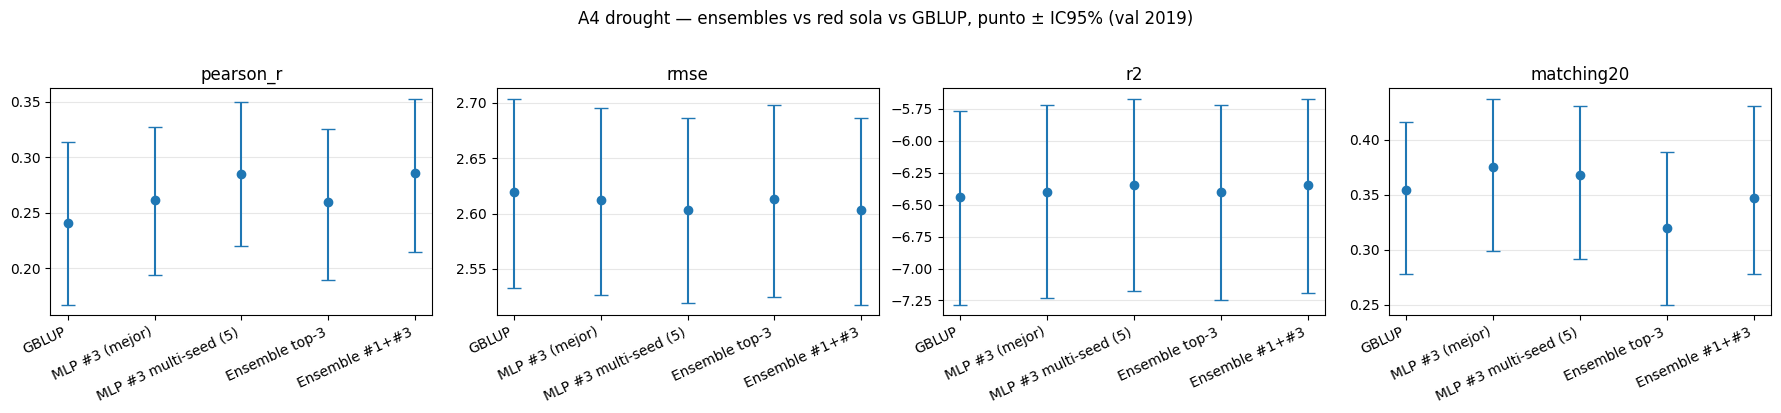

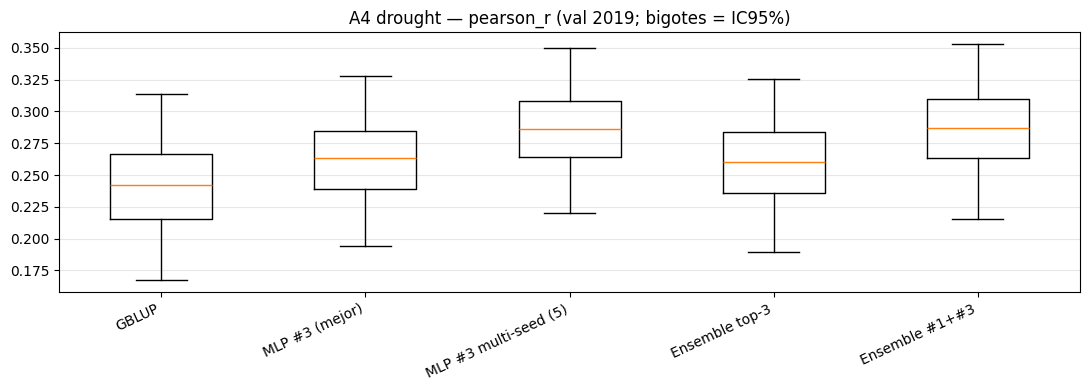

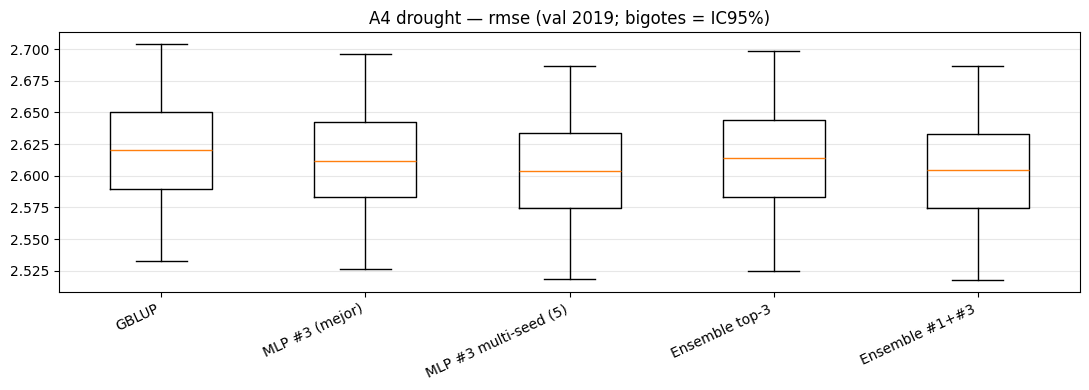

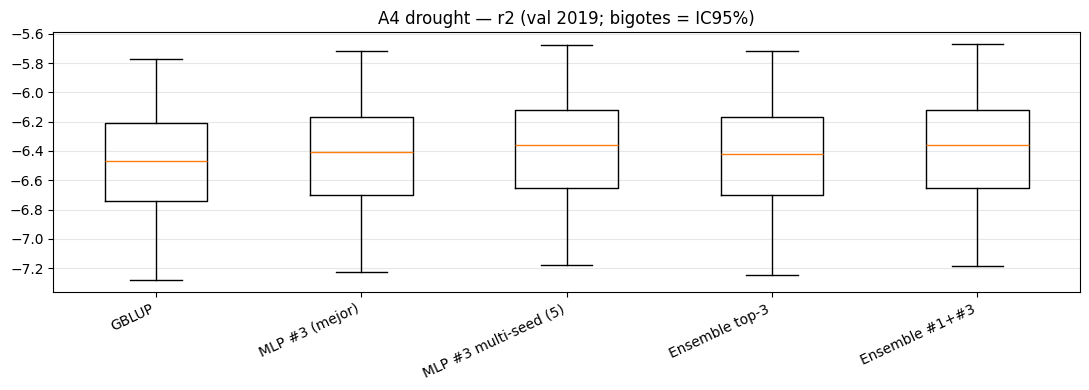

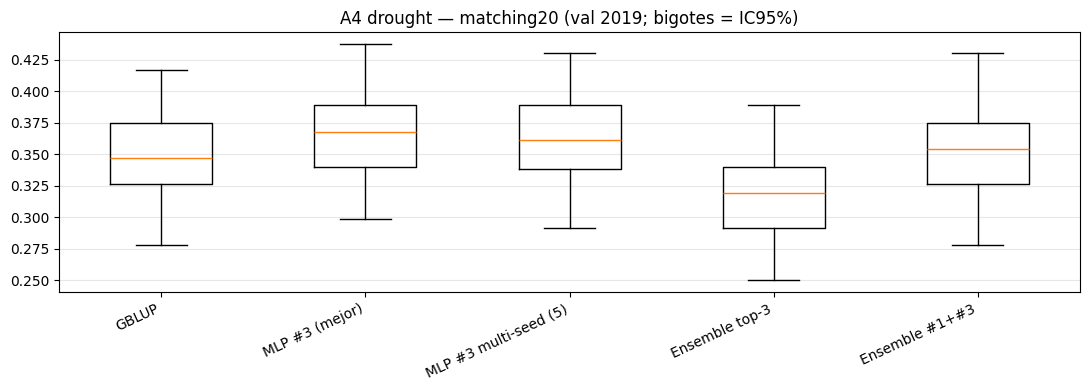

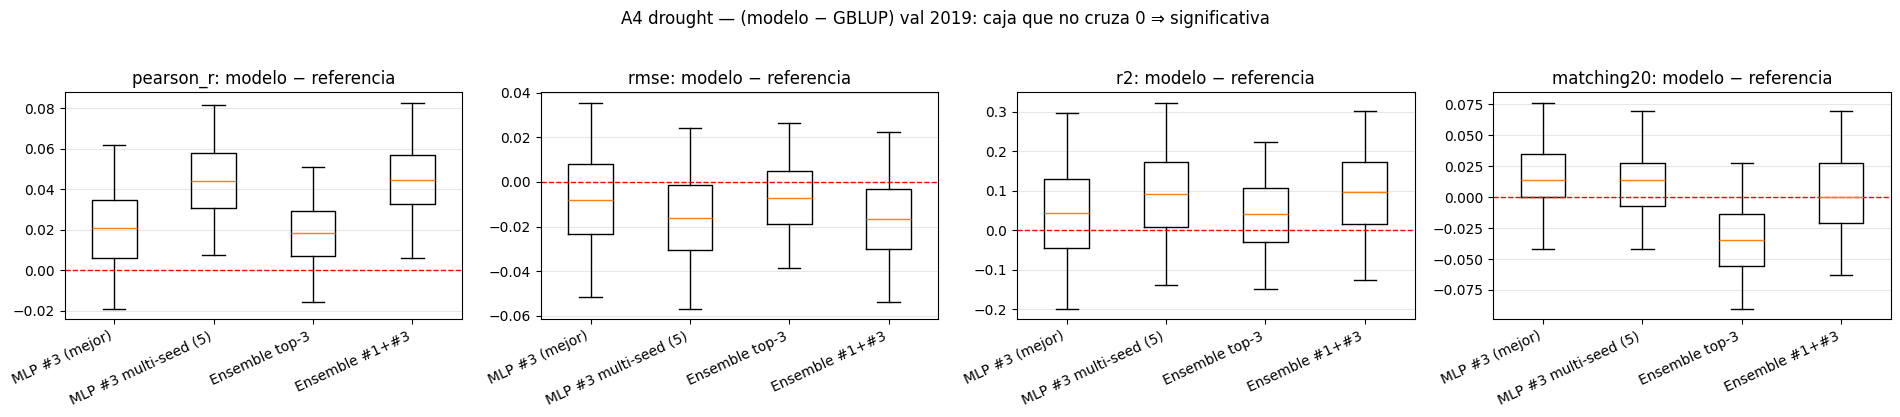


Diferencia pareada vs GBLUP drought (val 2019; * = IC95% no cruza 0):
  MLP #3 (mejor):
    pearson_r : delta=+0.021  IC95%[-0.019, +0.062]
    rmse      : delta=-0.008  IC95%[-0.052, +0.036]
    r2        : delta=+0.045  IC95%[-0.199, +0.298]
    matching20: delta=+0.016  IC95%[-0.042, +0.076]
  MLP #3 multi-seed (5):
    pearson_r : delta=+0.044  IC95%[+0.007, +0.082]  *
    rmse      : delta=-0.016  IC95%[-0.057, +0.024]
    r2        : delta=+0.093  IC95%[-0.137, +0.323]
    matching20: delta=+0.012  IC95%[-0.042, +0.069]
  Ensemble top-3:
    pearson_r : delta=+0.018  IC95%[-0.016, +0.051]
    rmse      : delta=-0.007  IC95%[-0.038, +0.026]
    r2        : delta=+0.039  IC95%[-0.150, +0.224]
    matching20: delta=-0.032  IC95%[-0.090, +0.028]
  Ensemble #1+#3:
    pearson_r : delta=+0.045  IC95%[+0.006, +0.083]  *
    rmse      : delta=-0.016  IC95%[-0.054, +0.022]
    r2        : delta=+0.093  IC95%[-0.125, +0.302]
    matching20: delta=+0.003  IC95%[-0.062, +0.069]


In [11]:
# === A4 (drought): ensembles de redes vs GBLUP, GY en sequía ==============================
# Requiere haber corrido la celda "Fase A · setup". Da 5 modelos: GBLUP, MLP#3 (mejor),
# MLP#3 multi-seed, ensemble top-3 y ensemble #1+#3 (las dos que superaban a GBLUP).
# Igual que A4: promedio/comparación sobre z-scores (escala arbitraria del MLP loss=pearson).
MLP_SWEEP_DROUGHT = "oromagnoli-/maze-genomic-pred/tt24pyzx"
MLP_BASE_DROUGHT  = "configs/exp_mlp_2017_to_2018_drought.yaml"
GBLUP_DROUGHT     = "configs/exp_gblup_2017_2018_to_2019_drought.yaml"
SEEDS = [575, 13, 71, 7, 100]                          # random_state del ensemble multi-seed

# top-3 del sweep drought (por pearson val 2018) + GBLUP; reentrenadas 2017+2018 -> 2019.
eval_with_preds("GBLUP drought", GBLUP_DROUGHT)
dr_top = []
for rank, (ov, _, _) in enumerate(top_runs_from_sweep(MLP_SWEEP_DROUGHT, k=3), start=1):
    eval_with_preds(f"MLP dr #{rank}", report_config(MLP_BASE_DROUGHT, ov))
    dr_top.append((ov, PREDS_BY_MODEL[f"MLP dr #{rank}"]))
ov3 = dr_top[2][0]                                     # HP de MLP #3 (la mejor en 2019)
# multi-seed de MLP #3: misma red con varias random_state.
dr_seed = []
for sd in SEEDS:
    eval_with_preds(f"MLP dr3 seed{sd}", report_config(MLP_BASE_DROUGHT, {**ov3, "model.params.random_state": sd}))
    dr_seed.append(PREDS_BY_MODEL[f"MLP dr3 seed{sd}"])

# Alinear todo a la misma intersección de líneas (val 2019, sequía).
ln, yt, yh = align_by_line(PREDS_BY_MODEL["GBLUP drought"], *[p for _, p in dr_top], *dr_seed)
ygb = yh[0]; y1, y2, y3 = yh[1], yh[2], yh[3]; yseed = yh[4:]
a4d_preds = {
    "GBLUP": ygb,
    "MLP #3 (mejor)": y3,
    f"MLP #3 multi-seed ({len(SEEDS)})": average_predictions(yseed, standardize=True),
    "Ensemble top-3": average_predictions([y1, y2, y3], standardize=True),
    "Ensemble #1+#3": average_predictions([y1, y3], standardize=True),
}
a4d_rows, a4d_samples = bootstrap_table(yt, a4d_preds, ENS_METRICS, group=ln,
                                        n_boot=N_BOOT, alpha=ALPHA, seed=575, standardize=True)
a4d_df = pd.DataFrame(a4d_rows)
print("Drought, val 2019 (Pearson/matching20 = portada; RMSE/R2 estandarizado, orientativo):")
display(a4d_df.pivot(index="model", columns="metric", values="point")[list(METRICS)].round(4))

save_show(plot_ci(a4d_df, title="A4 drought — ensembles vs red sola vs GBLUP, punto ± IC95% (val 2019)"),
          "a4_drought_ci.png")
for m in METRICS:                                      # 5 boxplots por métrica
    save_show(plot_box(a4d_samples, m, title=f"A4 drought — {m} (val 2019; bigotes = IC95%)"),
              f"a4_drought_box_{m}.png")
save_show(plot_paired_diff(a4d_samples, ref="GBLUP", metrics=METRICS,
                           title="A4 drought — (modelo − GBLUP) val 2019: caja que no cruza 0 ⇒ significativa"),
          "a4_drought_paired_diff.png")
print_paired(paired_diff_summary(a4d_samples, "GBLUP", METRICS, alpha=ALPHA),
             title="\nDiferencia pareada vs GBLUP drought (val 2019; * = IC95% no cruza 0):")


In [ ]:
MLP_SWEEP_DROUGHT = "oromagnoli-/maze-genomic-pred/tt24pyzx"
MLP_BASE_DROUGHT  = "configs/exp_mlp_2017_to_2018_drought.yaml"
GBLUP_DROUGHT     = "configs/exp_gblup_2017_2018_to_2019_drought.yaml"
N = 50
SEEDS = np.linspace(10, 5750, N)                         # random_state del ensemble multi-seed

# top-3 del sweep drought (por pearson val 2018) + GBLUP; reentrenadas 2017+2018 -> 2019.
eval_with_preds("GBLUP drought", GBLUP_DROUGHT)
dr_top = []
for rank, (ov, _, _) in enumerate(top_runs_from_sweep(MLP_SWEEP_DROUGHT, k=3), start=1):
    eval_with_preds(f"MLP dr #{rank}", report_config(MLP_BASE_DROUGHT, ov))
    dr_top.append((ov, PREDS_BY_MODEL[f"MLP dr #{rank}"]))
ov3 = dr_top[2][0]                                     # HP de MLP #3 (la mejor en 2019)
# multi-seed de MLP #3: misma red con varias random_state.
dr_seed = []
for sd in SEEDS:
    eval_with_preds(f"MLP dr3 seed{sd}", report_config(MLP_BASE_DROUGHT, {**ov3, "model.params.random_state": sd}))
    dr_seed.append(PREDS_BY_MODEL[f"MLP dr3 seed{sd}"])

# Alinear todo a la misma intersección de líneas (val 2019, sequía).
ln, yt, yh = align_by_line(PREDS_BY_MODEL["GBLUP drought"], *[p for _, p in dr_top], *dr_seed)
ygb = yh[0]; y1, y2, y3 = yh[1], yh[2], yh[3]; yseed = yh[4:]
a4d_preds = {
    "GBLUP": ygb,
    "MLP #3 (mejor)": y3,
    f"MLP #3 multi-seed ({len(SEEDS)})": average_predictions(yseed, standardize=True),
}
a4d_rows, a4d_samples = bootstrap_table(yt, a4d_preds, ENS_METRICS, group=ln,
                                        n_boot=N_BOOT, alpha=ALPHA, seed=575, standardize=True)
a4d_df = pd.DataFrame(a4d_rows)
print("Drought, val 2019 (Pearson/matching20 = portada; RMSE/R2 estandarizado, orientativo):")
display(a4d_df.pivot(index="model", columns="metric", values="point")[list(METRICS)].round(4))

save_show(plot_ci(a4d_df, title="A4 drought — ensembles vs red sola vs GBLUP, punto ± IC95% (val 2019)"),
          "a4_drought_ci.png")
for m in METRICS:                                      # boxplots por métrica
    save_show(plot_box(a4d_samples, m, title=f"A4 drought — {m} (val 2019; bigotes = IC95%)"),
              f"a4_drought_box_{m}.png")
save_show(plot_paired_diff(a4d_samples, ref="GBLUP", metrics=METRICS,
                           title="A4 drought — (modelo − GBLUP) val 2019: caja que no cruza 0 ⇒ significativa"),
          "a4_drought_paired_diff.png")
print_paired(paired_diff_summary(a4d_samples, "GBLUP", METRICS, alpha=ALPHA),
             title="\nDiferencia pareada vs GBLUP drought (val 2019; * = IC95% no cruza 0):")


## Fase B — MLP Multitask: comparación por trait (óptimo y sequía), un sweep por arm

Compara, **por trait** y en los **dos ambientes**, el MLP **multitask** (un tronco, una cabeza
por trait) contra el **MLP univariado** (single-task) y **GBLUP** del mismo trait. Métricas e
IC95% por cabeza usan SOLO las líneas con ese trait medido (máscara `Y_mask`); los deltas salen
del MISMO resample bootstrap (cluster por línea). Incluye los arms del *ablation*
(GY+PH+AD, GY+PH, GY+AD). 2020 sigue sellado.

Se reporta la **tabla de Pearson_r** (trait × modelo), los **gráficos de IC95% por trait** y un
**gráfico de matching20 para GY** (punto ± IC95% por modelo, mismo estilo que los de Pearson),
que es la métrica de utilidad para **seleccionar líneas**.

Toda la lógica vive en `src/eval/nb_eval.py` (`make_multitask_comparison`): el notebook solo
arma los dicts de configs/sweeps y llama. **Un sweep por arm × ambiente (6)**: pegá los ids en
`MT_SWEEPS_OPT`/`MT_SWEEPS_DRO` (vacío ⇒ HP base, con aviso). El univariado de **GY** sale de su
sweep single-task (`MLP_SWEEP` / `MLP_SWEEP_DROUGHT`); PH/AD univariado va con HP base.

**Qué modelo del sweep mostrar** (`ranks` al llamar `compare_env`): `(1,)` el mejor (default),
`(1, 2, 3)` el **top-3** de cada arm (la tabla se ensancha), `(2,)` solo el 2º mejor, etc.
Requiere la **Fase A · setup** corrida (hay fallback).

In [7]:
# === Fase B · setup (lógica en src/eval/nb_eval.py; un sweep por arm) ====================
from src.eval.nb_eval import make_multitask_comparison
from src.eval.metrics import pearson_r, rmse, r2, coincidence_index

METRICS   = globals().get("METRICS", ("pearson_r", "rmse", "r2", "matching20"))
N_BOOT    = globals().get("N_BOOT", 2000)
ALPHA     = globals().get("ALPHA", 0.05)
USE_CACHE = globals().get("USE_CACHE", True)
TRAITS    = ("GY", "PH", "AD")
ENS_METRICS = globals().get("ENS_METRICS", {
    "pearson_r": pearson_r, "rmse": rmse, "r2": r2,
    "matching20": lambda yt, yp: coincidence_index(yt, yp, 0.2)})
REPORT_CV = globals().get("REPORT_CV", {"scheme": "fixed_temporal", "val_year": 2019,
            "train_years": [2017, 2018], "holdout_test_year": 2020, "enforce_disjoint_lines": True})

# Univariado GY honesto: sweeps single-task por ambiente (los de la Fase A).
MLP_SWEEP         = globals().get("MLP_SWEEP", "oromagnoli-/maze-genomic-pred/kyl04lf5")
MLP_SWEEP_DROUGHT = globals().get("MLP_SWEEP_DROUGHT", "oromagnoli-/maze-genomic-pred/tt24pyzx")
MLP_BASE_OPT = globals().get("MLP_BASE", "configs/exp_mlp_2017_to_2018.yaml")
MLP_BASE_DRO = "configs/exp_mlp_2017_to_2018_drought.yaml"
GBLUP_BASE   = "configs/exp_gblup_2017_2018_to_2019.yaml"   # reml; se le overridea target/env

# eval_with_preds / PREDS_BY_MODEL vienen de la Fase A · setup; fallback si no.
try:
    eval_with_preds; PREDS_BY_MODEL
except NameError:
    from src.eval.nb_eval import make_evaluators
    _evm, eval_with_preds, _curv, PREDS_BY_MODEL = make_evaluators(
        METRICS, n_boot=N_BOOT, alpha=ALPHA, use_cache=USE_CACHE)

# Selection-bases multitask por arm, por ambiente (el sweep de cada uno parte de acá).
MT_BASES_OPT = {
    "MT (GY+PH+AD)": "configs/exp_mlp_multitask_2017_to_2018.yaml",
    "MT (GY+PH)":    "configs/exp_mlp_multitask_2017_to_2018_GY_PH.yaml",
    "MT (GY+AD)":    "configs/exp_mlp_multitask_2017_to_2018_GY_AD.yaml"}
MT_BASES_DRO = {
    "MT (GY+PH+AD)": "configs/exp_mlp_multitask_2017_to_2018_drought.yaml",
    "MT (GY+PH)":    "configs/exp_mlp_multitask_2017_to_2018_GY_PH_drought.yaml",
    "MT (GY+AD)":    "configs/exp_mlp_multitask_2017_to_2018_GY_AD_drought.yaml"}

MT_SWEEPS_OPT = {"MT (GY+PH+AD)": "oromagnoli-/maze-genomic-pred/yj2h9x3g", "MT (GY+PH)": "oromagnoli-/maze-genomic-pred/habh6k13", "MT (GY+AD)": "oromagnoli-/maze-genomic-pred/fgi4igyb"}
MT_SWEEPS_DRO = {"MT (GY+PH+AD)": "oromagnoli-/maze-genomic-pred/ivr804mj", "MT (GY+PH)": "oromagnoli-/maze-genomic-pred/3hehgtwx", "MT (GY+AD)": "oromagnoli-/maze-genomic-pred/92k7ybzc"}

compare_env = make_multitask_comparison(
    eval_with_preds=eval_with_preds, preds_by_model=PREDS_BY_MODEL, report_cv=REPORT_CV,
    metrics=METRICS, ens_metrics=ENS_METRICS, traits=TRAITS,
    n_boot=N_BOOT, alpha=ALPHA, use_cache=USE_CACHE)
print("[ok] Fase B setup listo. ranks=(1,) por defecto; ranks=(1, 2, 3) = top-3 por arm.")

[ok] Fase B setup listo. ranks=(1,) por defecto; ranks=(1, 2, 3) = top-3 por arm.


wandb: [wandb.Api()] Loaded credentials for https://api.wandb.ai from C:\Users\MODDE\.netrc.


  [cache hit] MT (GY+PH+AD) optimal (e1065103705ca3af)
  [cache hit] MT (GY+PH) optimal (fd3e9cf69a6c2f70)
  [cache hit] MT (GY+AD) optimal (b096cebcb1eb28ac)
  [cache hit] Univariado GY optimal (77c60131156e720c)
  [cache hit] GBLUP GY optimal (90f1d6fe13802d36)
  [cache hit] Univariado PH optimal (94881d954ea8a9ee)
  [cache hit] GBLUP PH optimal (dd7eb77eb1ffb2f2)
  [cache hit] Univariado AD optimal (21a182ebdf0c04ed)
  [cache hit] GBLUP AD optimal (df6b489366ccaf6e)


model,GBLUP,MT (GY+AD),MT (GY+PH),MT (GY+PH+AD),Univariado
trait,,,,,
GY,0.3145,0.3207,0.2336,0.3368,0.2618
PH,0.0714,NaN,0.0845,0.1068,0.0979
AD,0.2981,0.1904,NaN,0.1368,0.3125


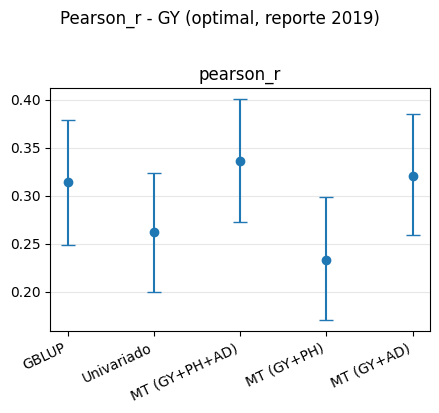

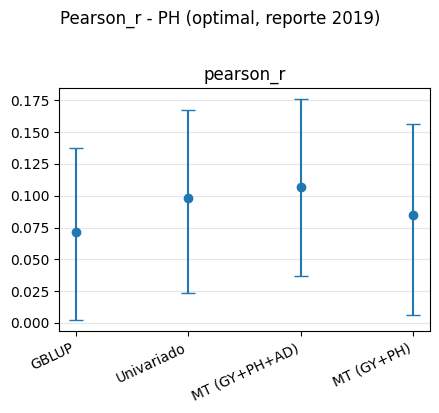

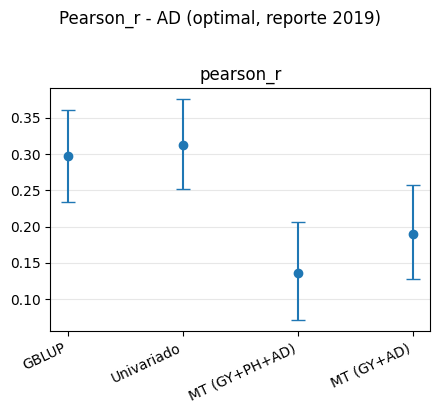

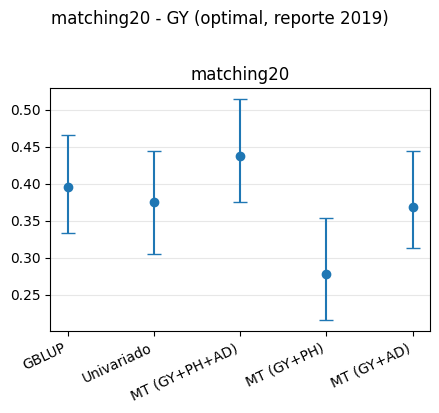

In [3]:
# === Fase B · ÓPTIMO — Multitask vs Univariado vs GBLUP por trait =========================
# ranks: (1,) mejor de cada sweep | (1, 2, 3) top-3 | (2,) solo el 2do mejor.
res_opt = compare_env("optimal", mt_bases=MT_BASES_OPT, mt_sweeps=MT_SWEEPS_OPT,
                      gblup_base=GBLUP_BASE, mlp_base=MLP_BASE_OPT, gy_sweep=MLP_SWEEP, ranks=(1,))
display(res_opt["wide"].round(4))                       # Pearson_r por trait × modelo
for trait, fig in res_opt["figs"].items():             # gráficos pearson_r (punto ± IC95%) por trait
    if "save_show" in globals():
        save_show(fig, f"faseB_optimal_{trait}_pearson_ci.png")
if "save_show" in globals():                            # matching20 de GY (mismo estilo, punto ± IC95%)
    save_show(res_opt["fig_match_gy"], "faseB_optimal_GY_matching20_ci.png")

  [cache hit] Univariado GY drought (2f23414828d753c2)
  [cache hit] GBLUP GY drought (63b22b6cf2c94997)


model,GBLUP,MT (GY+AD),MT (GY+PH),MT (GY+PH+AD),Univariado
trait,,,,,
GY,0.2413,0.2721,0.1527,0.2209,0.2619
PH,-0.0478,NaN,-0.0940,-0.0782,-0.0974
AD,0.3170,0.2636,NaN,0.3034,0.3084


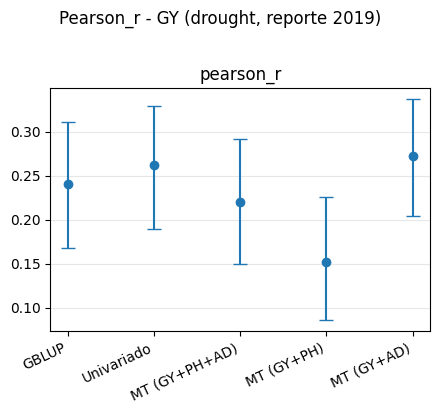

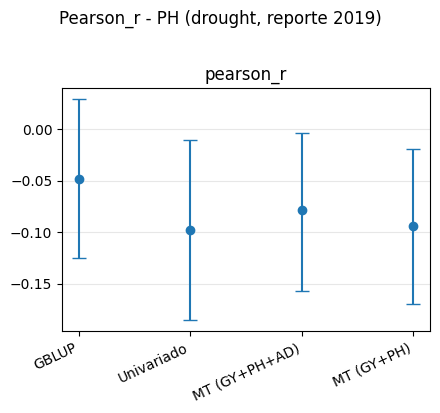

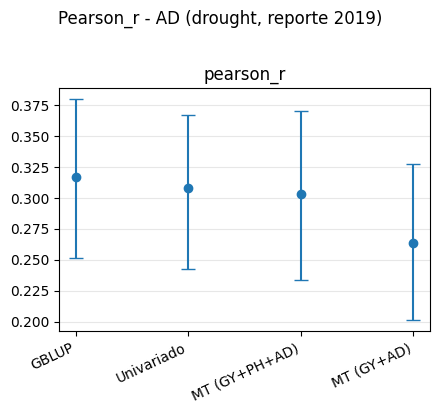

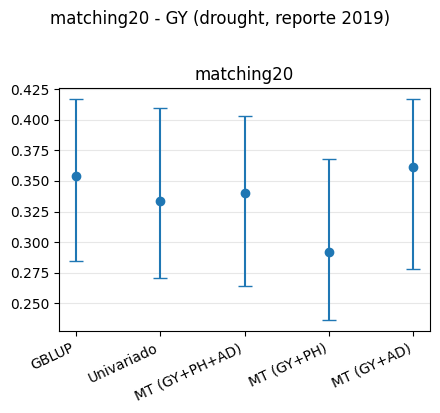

In [4]:
# === Fase B · SEQUÍA (drought) — Multitask vs Univariado vs GBLUP por trait ===============
res_dro = compare_env("drought", mt_bases=MT_BASES_DRO, mt_sweeps=MT_SWEEPS_DRO,
                      gblup_base=GBLUP_BASE, mlp_base=MLP_BASE_DRO, gy_sweep=MLP_SWEEP_DROUGHT, ranks=(1,))
display(res_dro["wide"].round(4))                       # Pearson_r por trait × modelo
for trait, fig in res_dro["figs"].items():             # gráficos pearson_r (punto ± IC95%) por trait
    if "save_show" in globals():
        save_show(fig, f"faseB_drought_{trait}_pearson_ci.png")
if "save_show" in globals():                            # matching20 de GY (mismo estilo, punto ± IC95%)
    save_show(res_dro["fig_match_gy"], "faseB_drought_GY_matching20_ci.png")

  [cache hit] Univariado GY optimal (77c60131156e720c)
  [cache hit] GBLUP GY optimal (90f1d6fe13802d36)
  [cache hit] Univariado PH optimal (94881d954ea8a9ee)
  [cache hit] GBLUP PH optimal (dd7eb77eb1ffb2f2)
  [cache hit] Univariado AD optimal (21a182ebdf0c04ed)
  [cache hit] GBLUP AD optimal (df6b489366ccaf6e)


model,GBLUP,MT (GY+AD) #2,MT (GY+AD) #3,MT (GY+PH) #2,MT (GY+PH) #3,MT (GY+PH+AD) #2,MT (GY+PH+AD) #3,Univariado
trait,,,,,,,,
GY,0.3145,0.3041,0.3189,0.1889,0.2238,0.2382,0.1957,0.2618
PH,0.0714,NaN,NaN,0.1621,0.1482,0.0143,0.1370,0.0979
AD,0.2981,0.2364,0.2013,NaN,NaN,0.2436,0.2315,0.3125


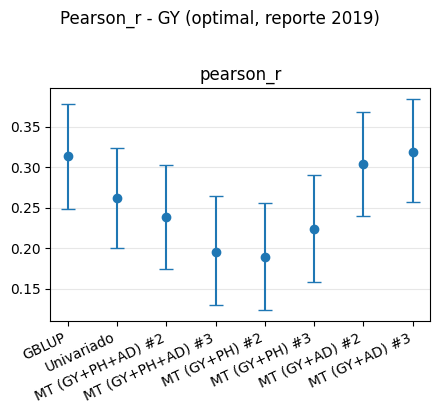

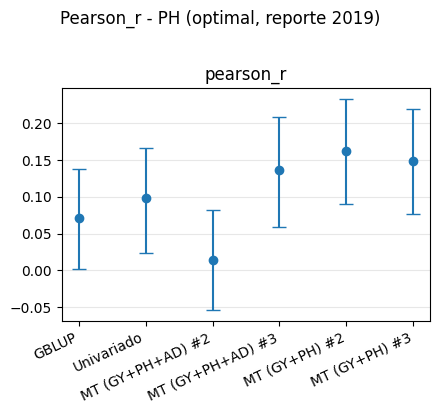

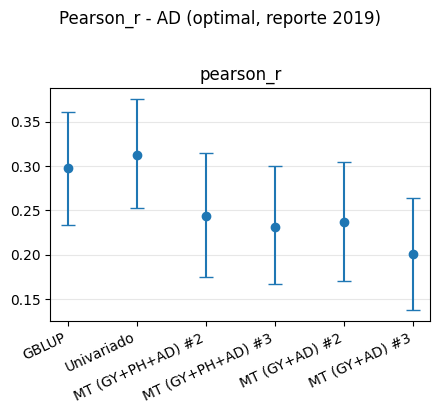

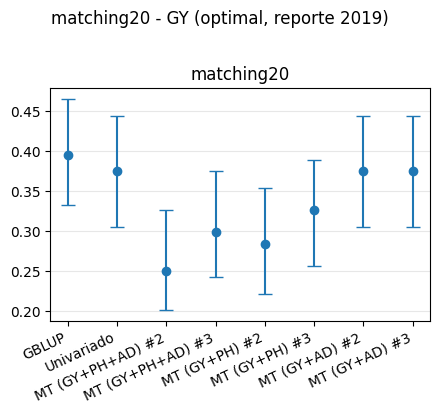

In [5]:
# === Fase B · ÓPTIMO — Multitask vs Univariado vs GBLUP por trait =========================
# ranks: (1,) mejor de cada sweep | (1, 2, 3) top-3 | (2,) solo el 2do mejor.
res_opt = compare_env("optimal", mt_bases=MT_BASES_OPT, mt_sweeps=MT_SWEEPS_OPT,
                      gblup_base=GBLUP_BASE, mlp_base=MLP_BASE_OPT, gy_sweep=MLP_SWEEP, ranks=(2, 3))
display(res_opt["wide"].round(4))                       # Pearson_r por trait × modelo
for trait, fig in res_opt["figs"].items():             # gráficos pearson_r (punto ± IC95%) por trait
    if "save_show" in globals():
        save_show(fig, f"faseB_optimal_{trait}_pearson_ci.png")
if "save_show" in globals():                            # matching20 de GY (mismo estilo, punto ± IC95%)
    save_show(res_opt["fig_match_gy"], "faseB_optimal_GY_matching20_ci.png")

  [cache hit] Univariado GY drought (2f23414828d753c2)
  [cache hit] GBLUP GY drought (63b22b6cf2c94997)
  [cache hit] Univariado PH drought (a27584dca738baf6)
  [cache hit] GBLUP PH drought (f2257afb81ec2338)
  [cache hit] Univariado AD drought (fc715e38d6373056)
  [cache hit] GBLUP AD drought (5d68a85333bb7ca7)


model,GBLUP,MT (GY+AD) #2,MT (GY+AD) #3,MT (GY+PH) #2,MT (GY+PH) #3,MT (GY+PH+AD) #2,MT (GY+PH+AD) #3,Univariado
trait,,,,,,,,
GY,0.2413,0.2737,0.3992,0.1068,0.3469,0.2424,0.3093,0.2619
PH,-0.0478,NaN,NaN,-0.0832,0.0599,-0.0315,-0.1020,-0.0974
AD,0.3170,0.3145,0.2660,NaN,NaN,0.1674,0.2558,0.3084


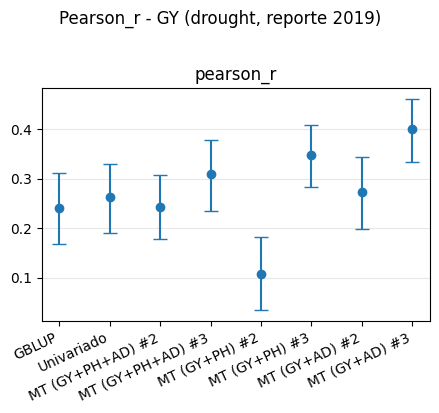

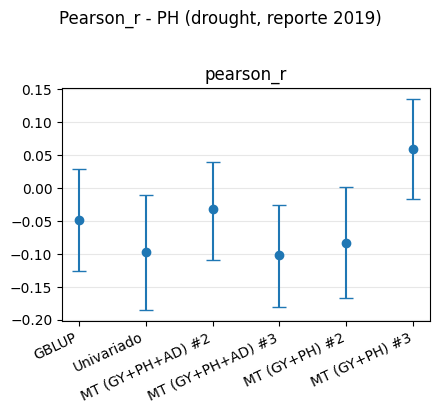

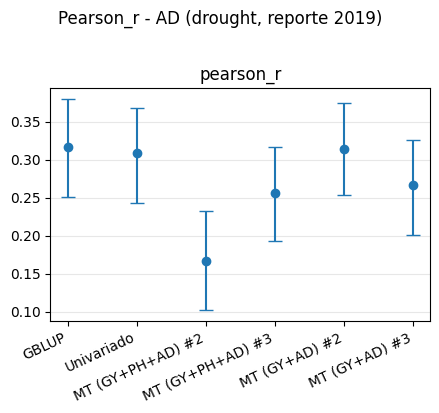

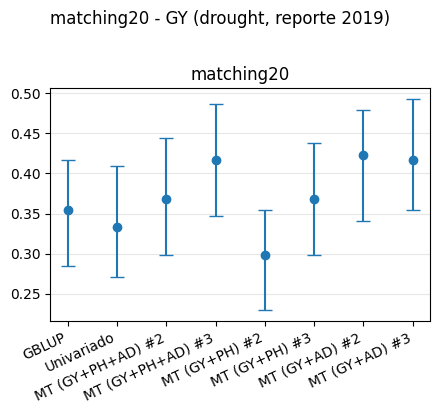

In [6]:
# === Fase B · SEQUÍA (drought) — Multitask vs Univariado vs GBLUP por trait ===============
res_dro = compare_env("drought", mt_bases=MT_BASES_DRO, mt_sweeps=MT_SWEEPS_DRO,
                      gblup_base=GBLUP_BASE, mlp_base=MLP_BASE_DRO, gy_sweep=MLP_SWEEP_DROUGHT, ranks=(2, 3))
display(res_dro["wide"].round(4))                       # Pearson_r por trait × modelo
for trait, fig in res_dro["figs"].items():             # gráficos pearson_r (punto ± IC95%) por trait
    if "save_show" in globals():
        save_show(fig, f"faseB_drought_{trait}_pearson_ci.png")
if "save_show" in globals():                            # matching20 de GY (mismo estilo, punto ± IC95%)
    save_show(res_dro["fig_match_gy"], "faseB_drought_GY_matching20_ci.png")

## GBLUP-residual · stacking aditivo GBLUP + red sobre el residual

La red predice el residual `GY − ŷ_GBLUP` y la predicción final es la suma `ŷ_GBLUP + ŷ_red`
(captura solo lo no-lineal que GBLUP no explica; es un stacking aditivo *entrenado*, distinto
del blend convexo A3). Se toma el **mejor HP del sweep** (elegido en val 2018, honesto), se
**reentrena 2017+2018 → 2019** con `report_config`, y se compara contra el GBLUP base. Portada =
Pearson (invariante al shift de media entre años); RMSE/R² de apoyo.

mejor del sweep: run 7ltwjhxe | pearson_r_mean(val 2018) = 0.3813
  [cache hit] GBLUP (90f1d6fe13802d36)
  [cache hit] GBLUP+resid (red) (ddb12fd21da017ef)

Reporte en val 2019 (reentrenado 2017+2018; Pearson = portada; RMSE/R2 de apoyo):


metric,pearson_r,rmse,r2,matching20
model,,,,
GBLUP,0.3145,1.3016,-0.6644,0.3958
GBLUP+resid (red),0.2516,1.4950,-1.1956,0.3611


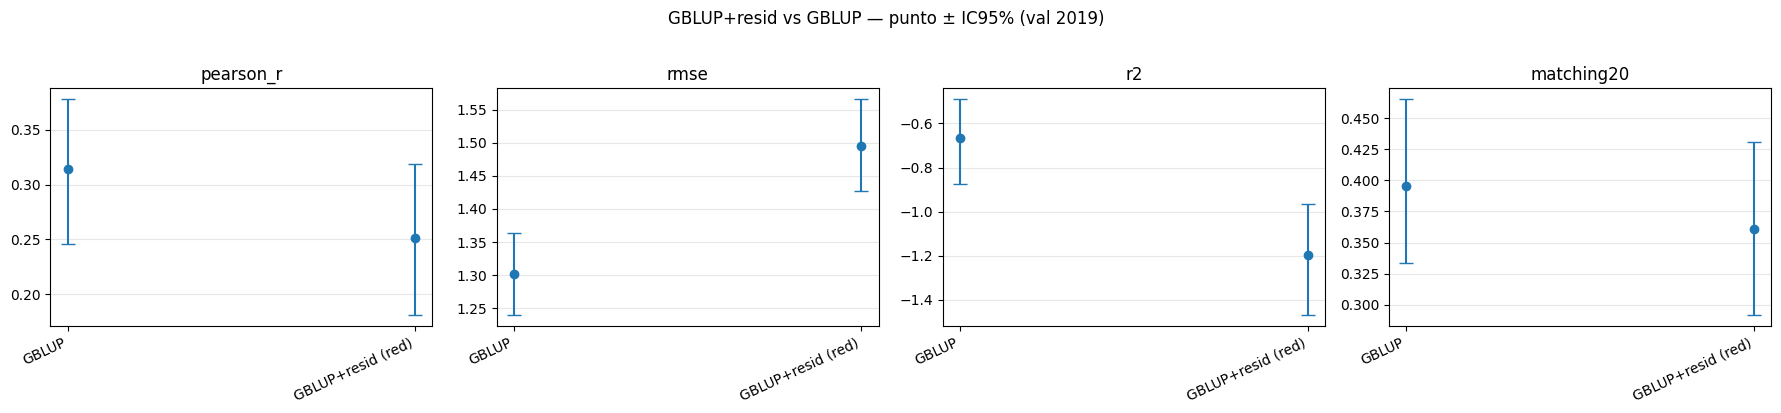

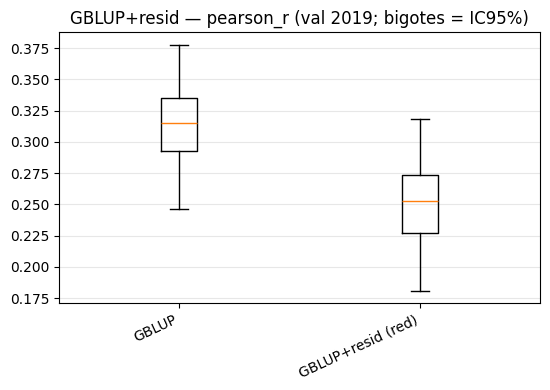

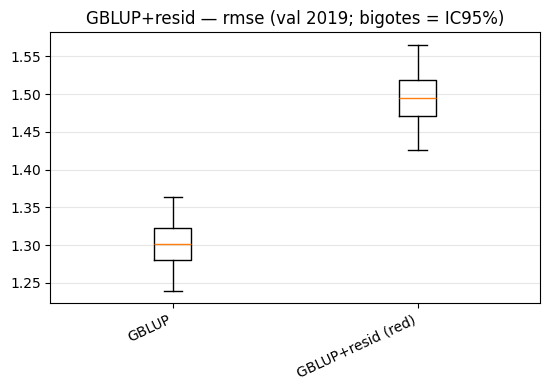

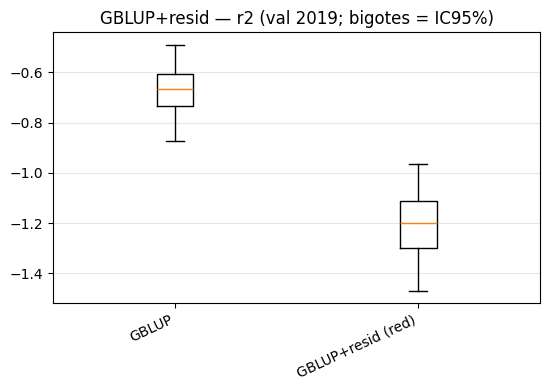

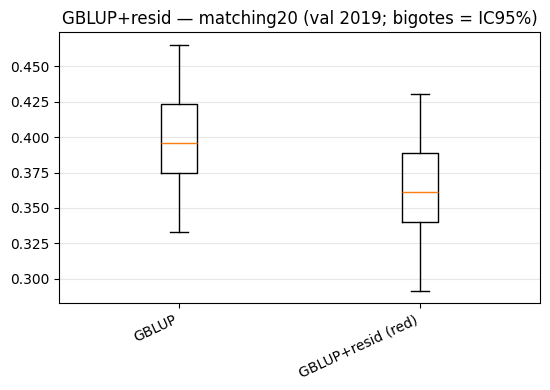

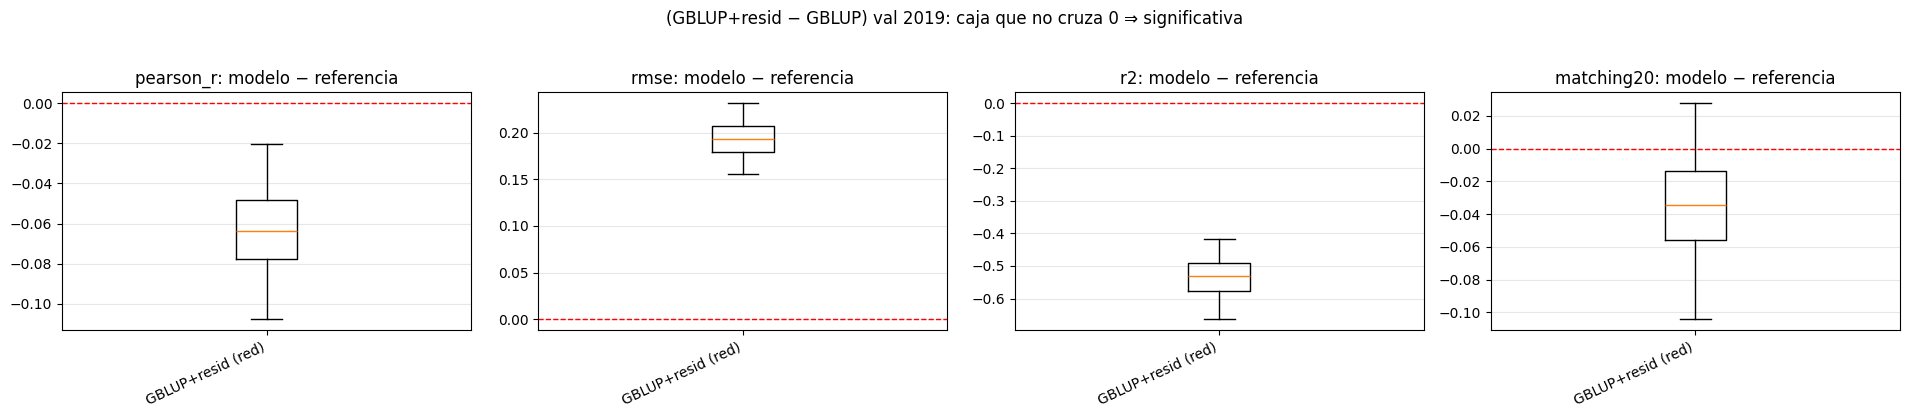


Diferencia pareada vs GBLUP (val 2019; * = IC95% no cruza 0):
  GBLUP+resid (red):
    pearson_r : delta=-0.063  IC95%[-0.108, -0.021]  *
    rmse      : delta=+0.194  IC95%[+0.156, +0.232]  *
    r2        : delta=-0.535  IC95%[-0.663, -0.418]  *
    matching20: delta=-0.037  IC95%[-0.104, +0.028]


In [9]:
# === GBLUP-residual · REPORTE en 2019 (mejor del sweep, reentrenado 2017+2018) ============
GBLUP_RESID_BASE  = "configs/exp_gblup_residual_2017_to_2018.yaml"
GBLUP_RESID_SWEEP = "oromagnoli-/maze-genomic-pred/o4kl9qbz"   # <-- pegar tras correr el sweep

# Mejor HP del sweep (elegido por pearson_r_mean en val 2018, sin tocar 2019).
ov_best, p2018, rid = best_run_from_sweep(GBLUP_RESID_SWEEP)
print(f"mejor del sweep: run {rid} | pearson_r_mean(val 2018) = {p2018:.4f}")

# Reentrena 2017+2018 -> 2019 (report_config pisa el cv al de REPORTE) y compara vs GBLUP base.
gr_rows, gr_samples = [], {}
r, s = evaluate_model("GBLUP", GBLUP_2019);              gr_rows += r; gr_samples["GBLUP"] = s
r, s = evaluate_model("GBLUP+resid (red)", report_config(GBLUP_RESID_BASE, ov_best))
gr_rows += r; gr_samples["GBLUP+resid (red)"] = s

gr_df = pd.DataFrame(gr_rows)
print("\nReporte en val 2019 (reentrenado 2017+2018; Pearson = portada; RMSE/R2 de apoyo):")
display(gr_df.pivot(index="model", columns="metric", values="point")[list(METRICS)].round(4))

# Errorbar IC95%, boxplots por métrica y diferencia pareada (mismo bootstrap cluster por línea).
save_show(plot_ci(gr_df, title="GBLUP+resid vs GBLUP — punto ± IC95% (val 2019)"), "gblup_resid_ci.png")
for m in METRICS:
    save_show(plot_box(gr_samples, m, title=f"GBLUP+resid — {m} (val 2019; bigotes = IC95%)"),
              f"gblup_resid_box_{m}.png")
save_show(plot_paired_diff(gr_samples, ref="GBLUP", metrics=METRICS,
                           title="(GBLUP+resid − GBLUP) val 2019: caja que no cruza 0 ⇒ significativa"),
          "gblup_resid_paired.png")
print_paired(paired_diff_summary(gr_samples, "GBLUP", METRICS, alpha=ALPHA),
             title="\nDiferencia pareada vs GBLUP (val 2019; * = IC95% no cruza 0):")